In [3]:
!pip install -q transformers accelerate nibabel \
    scikit-learn matplotlib pandas tqdm


In [4]:

import os
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
import torch

from pathlib import Path
from tqdm.auto import tqdm

from transformers import ViTMAEForPreTraining

# Google Drive
from google.colab import drive
drive.mount("/content/drive")

# Project paths
BASE_PATH = Path(
    "/content/drive/MyDrive/Breast_Cancer_AI_Project"
)

DATA_PATH = BASE_PATH / "data" / "BreastDCEDL_ISPY1_min_crop"

CLEANED_PATH = BASE_PATH / "data" / "cleaned"

MASTER_CSV = CLEANED_PATH / "patient_master.csv"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", DEVICE)
print("CUDA available:", torch.cuda.is_available())
print("Project exists:", BASE_PATH.exists())
print("Master CSV exists:", MASTER_CSV.exists())


Mounted at /content/drive
Device: cuda
CUDA available: True
Project exists: True
Master CSV exists: True


In [5]:

# ==========================================
# SECTION 2 — DATASET AND GPU AUDIT
# ==========================================

print("GPU:", torch.cuda.get_device_name(0)
      if torch.cuda.is_available() else "No GPU")

master = pd.read_csv(MASTER_CSV)

# Only patients with known pCR labels
labeled = master[master["pCR"].notna()].copy()

print("\nTotal patients:", len(master))
print("Patients with pCR labels:", len(labeled))
print("Missing pCR labels:", master["pCR"].isna().sum())

print("\nPatient splits:")
print(labeled["split"].value_counts())

print("\npCR distribution:")
print(labeled["pCR"].value_counts())

print("\npCR distribution by split:")
print(pd.crosstab(labeled["split"], labeled["pCR"]))

print("\nMRI files available:")
print("DCE 0:", master["dce_0"].notna().sum())
print("DCE 1:", master["dce_1"].notna().sum())
print("DCE 2:", master["dce_2"].notna().sum())

print("\nTumour masks available:", master["mask"].notna().sum())


GPU: Tesla T4

Total patients: 172
Patients with pCR labels: 171
Missing pCR labels: 1

Patient splits:
split
train         119
validation     26
test           26
Name: count, dtype: int64

pCR distribution:
pCR
0.0    122
1.0     49
Name: count, dtype: int64

pCR distribution by split:
pCR         0.0  1.0
split               
test         18    8
train        85   34
validation   19    7

MRI files available:
DCE 0: 172
DCE 1: 172
DCE 2: 172

Tumour masks available: 172


In [6]:

# ==========================================
# SECTION 3 — LOAD PRETRAINED VIT-MAE
# ==========================================

from transformers import ViTMAEForPreTraining

MODEL_NAME = "facebook/vit-mae-base"

model = ViTMAEForPreTraining.from_pretrained(
    MODEL_NAME
)

model = model.to(DEVICE)

print("Model loaded successfully!")

print("Image size:", model.config.image_size)
print("Patch size:", model.config.patch_size)
print("Mask ratio:", model.config.mask_ratio)
print("Hidden dimension:", model.config.hidden_size)
print("Input channels:", model.config.num_channels)

print("\nTrainable parameters:",
      sum(p.numel() for p in model.parameters()
          if p.requires_grad))


config.json:   0%|          | 0.00/676 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  448MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/334 [00:00<?, ?it/s]

Model loaded successfully!
Image size: 224
Patch size: 16
Mask ratio: 0.75
Hidden dimension: 768
Input channels: 3

Trainable parameters: 111907840


In [7]:

# ==========================================
# SECTION 4 — INSPECT ONE PATIENT'S MRI DATA
# ==========================================

import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Select one patient from the training split
sample = master[master["split"] == "train"].iloc[0]

print("Patient ID:", sample["pid"])

# Resolve MRI and mask paths
def resolve_path(path_value):
    if pd.isna(path_value):
        return None

    path_value = Path(str(path_value))

    candidates = [
        path_value,
        BASE_PATH / path_value,
        DATA_PATH / path_value,
        CLEANED_PATH / path_value
    ]

    for candidate in candidates:
        if candidate.exists():
            return candidate

    return None


# Load the three DCE phases and tumour mask
volume_paths = {
    "Pre-contrast": resolve_path(sample["dce_0"]),
    "Early post-contrast": resolve_path(sample["dce_1"]),
    "Late post-contrast": resolve_path(sample["dce_2"]),
    "Tumour mask": resolve_path(sample["mask"])
}

for name, path in volume_paths.items():
    print(f"{name}: {path}")

if any(path is None for path in volume_paths.values()):
    raise FileNotFoundError(
        "At least one MRI or mask path could not be resolved. "
        "Check the printed paths."
    )

# Load NIfTI volumes
volumes = {}

for name, path in volume_paths.items():
    nii = nib.load(str(path))
    volumes[name] = nii.get_fdata(dtype=np.float32)

    print(
        f"\n{name}",
        "\nShape:", volumes[name].shape,
        "\nSpacing:", nii.header.get_zooms()[:3],
        "\nAffine:\n", nii.affine
    )

# Check dimensions
shapes = [volume.shape for volume in volumes.values()]

print("\nAll shapes:", shapes)
print("All shapes match:", len(set(shapes)) == 1)

# Check tumour mask
mask = volumes["Tumour mask"]

print("\nMask unique values:", np.unique(mask)[:20])
print("Tumour voxels:", np.count_nonzero(mask))

# Find slices containing tumour
tumour_slices = np.where(
    np.any(mask > 0, axis=(0, 1))
)[0]

print("Slices containing tumour:", tumour_slices)
print("Number of tumour-containing slices:", len(tumour_slices))


Patient ID: ISPY1_1001
Pre-contrast: /content/drive/MyDrive/Breast_Cancer_AI_Project/data/BreastDCEDL_ISPY1_min_crop/dce/ISPY1_1001_spy1_vis1_dce_aqc_0.nii.gz
Early post-contrast: /content/drive/MyDrive/Breast_Cancer_AI_Project/data/BreastDCEDL_ISPY1_min_crop/dce/ISPY1_1001_spy1_vis1_dce_aqc_1.nii.gz
Late post-contrast: /content/drive/MyDrive/Breast_Cancer_AI_Project/data/BreastDCEDL_ISPY1_min_crop/dce/ISPY1_1001_spy1_vis1_dce_aqc_2.nii.gz
Tumour mask: /content/drive/MyDrive/Breast_Cancer_AI_Project/data/BreastDCEDL_ISPY1_min_crop/mask/ISPY1_1001_spy1_vis1_mask.nii.gz

Pre-contrast 
Shape: (30, 256, 256) 
Spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0)) 
Affine:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

Early post-contrast 
Shape: (30, 256, 256) 
Spacing: (np.float32(1.0), np.float32(1.0), np.float32(1.0)) 
Affine:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

Late post-contrast 
Shape: (30, 256, 256) 
Spacing: (np.float32(1.0), np.floa

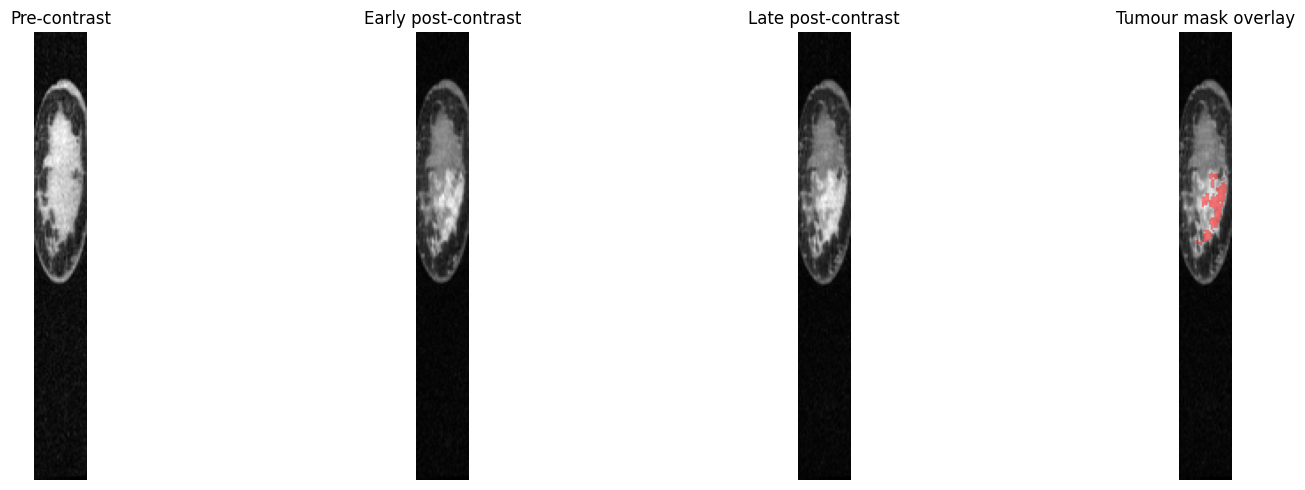

In [8]:

# ==========================================
# SECTION 5 — VISUALIZE MRI AND TUMOUR MASK
# ==========================================

if len(tumour_slices) == 0:
    raise ValueError("No tumour voxels found in this patient's mask.")

# Select the middle tumour-containing slice
slice_idx = tumour_slices[len(tumour_slices) // 2]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

phases = [
    "Pre-contrast",
    "Early post-contrast",
    "Late post-contrast"
]

for i, phase in enumerate(phases):
    image = volumes[phase][:, :, slice_idx]

    axes[i].imshow(image.T, cmap="gray", origin="lower")
    axes[i].set_title(phase)
    axes[i].axis("off")

# Show tumour mask overlaid on late post-contrast MRI
late_image = volumes["Late post-contrast"][:, :, slice_idx]
mask_slice = mask[:, :, slice_idx]

axes[3].imshow(late_image.T, cmap="gray", origin="lower")
axes[3].imshow(
    np.ma.masked_where(mask_slice.T == 0, mask_slice.T),
    cmap="autumn",
    alpha=0.5,
    origin="lower"
)
axes[3].set_title("Tumour mask overlay")
axes[3].axis("off")

plt.tight_layout()
plt.show()



Axis 0:
Tumour-containing positions: 26
First position: 2
Last position: 27

Axis 1:
Tumour-containing positions: 73
First position: 110
Last position: 191

Axis 2:
Tumour-containing positions: 85
First position: 59
Last position: 143

Tumour slices along axis 0: [ 2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25
 26 27]


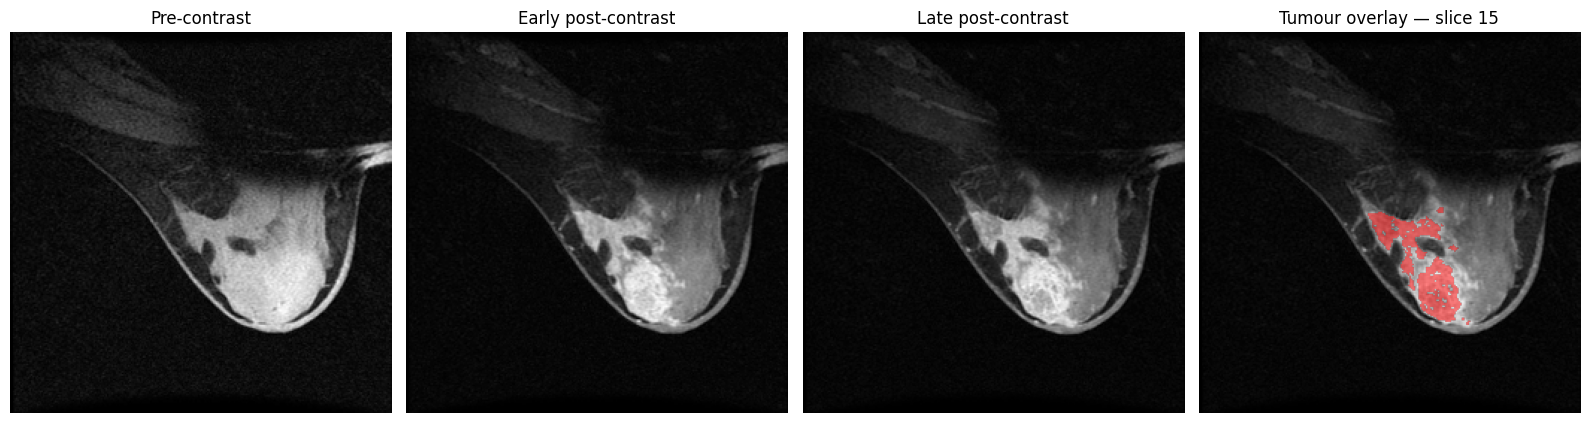

In [9]:

# ==========================================
# SECTION 6 — CHECK TUMOUR DISTRIBUTION
# ==========================================

mask = volumes["Tumour mask"]

for axis in range(3):
    other_axes = tuple(i for i in range(3) if i != axis)

    occupied = np.where(
        np.any(mask > 0, axis=other_axes)
    )[0]

    print(f"\nAxis {axis}:")
    print("Tumour-containing positions:", len(occupied))

    if len(occupied) > 0:
        print("First position:", occupied[0])
        print("Last position:", occupied[-1])

# For a (30, 256, 256) volume, inspect slices along axis 0
tumour_slices_axis0 = np.where(
    np.any(mask > 0, axis=(1, 2))
)[0]

print("\nTumour slices along axis 0:", tumour_slices_axis0)

if len(tumour_slices_axis0) == 0:
    raise ValueError("No tumour found along axis 0.")

z = tumour_slices_axis0[len(tumour_slices_axis0) // 2]

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

phases = [
    "Pre-contrast",
    "Early post-contrast",
    "Late post-contrast"
]

for i, phase in enumerate(phases):
    image = volumes[phase][z, :, :]

    axes[i].imshow(image.T, cmap="gray", origin="lower")
    axes[i].set_title(phase)
    axes[i].axis("off")

late_image = volumes["Late post-contrast"][z, :, :]
mask_slice = mask[z, :, :]

axes[3].imshow(late_image.T, cmap="gray", origin="lower")
axes[3].imshow(
    np.ma.masked_where(mask_slice.T == 0, mask_slice.T),
    cmap="autumn",
    alpha=0.5,
    origin="lower"
)
axes[3].set_title(f"Tumour overlay — slice {z}")
axes[3].axis("off")

plt.tight_layout()
plt.show()


In [10]:

# ==========================================
# SECTION 7 — CREATE TUMOUR-CENTRED MRI CROPS
# ==========================================

import torch.nn.functional as F

IMAGE_SIZE = 224
CROP_MARGIN = 20

def create_patient_crops(volumes, margin=CROP_MARGIN):
    """
    Extract tumour-containing 2D slices.
    Input volume shape: (30, 256, 256)

    Output shape: (number_of_slices, 3, 224, 224)
    Channel order: pre, early, late
    """

    pre = volumes["Pre-contrast"]
    early = volumes["Early post-contrast"]
    late = volumes["Late post-contrast"]
    mask = volumes["Tumour mask"]

    # Verify dimensions
    if not (pre.shape == early.shape == late.shape == mask.shape):
        raise ValueError("MRI and mask dimensions do not match.")

    # Find tumour-containing slices along axis 0
    tumour_slices = np.where(
        np.any(mask > 0, axis=(1, 2))
    )[0]

    if len(tumour_slices) == 0:
        raise ValueError("Empty tumour mask.")

    # Find one common in-plane bounding box
    coords = np.where(mask > 0)

    y_min, y_max = coords[1].min(), coords[1].max()
    x_min, x_max = coords[2].min(), coords[2].max()

    # Add surrounding tissue margin
    y_min = max(0, y_min - margin)
    y_max = min(mask.shape[1], y_max + margin + 1)

    x_min = max(0, x_min - margin)
    x_max = min(mask.shape[2], x_max + margin + 1)

    # Common patient-wise intensity normalization
    combined = np.concatenate([
        pre.ravel(), early.ravel(), late.ravel()
    ])

    low, high = np.percentile(combined, [1, 99])

    if high <= low:
        raise ValueError("Invalid intensity range.")

    normalized_phases = []

    for volume in [pre, early, late]:
        normalized = np.clip(
            (volume - low) / (high - low),
            0, 1
        )
        normalized_phases.append(normalized)

    images = []

    for slice_idx in tumour_slices:

        # Apply identical crop to all three phases
        channels = []

        for volume in normalized_phases:
            crop = volume[
                slice_idx,
                y_min:y_max,
                x_min:x_max
            ]

            tensor = torch.from_numpy(
                crop.astype(np.float32)
            )[None, None, :, :]

            resized = F.interpolate(
                tensor,
                size=(IMAGE_SIZE, IMAGE_SIZE),
                mode="bilinear",
                align_corners=False
            )

            channels.append(resized.squeeze(0))

        # Stack into (3, 224, 224)
        image = torch.cat(channels, dim=0)
        images.append(image)

    return torch.stack(images), tumour_slices


# Test on the sample patient
sample_images, sample_slices = create_patient_crops(volumes)

print("Extracted images:", sample_images.shape)
print("Tumour slices:", len(sample_slices))
print("Minimum intensity:", sample_images.min().item())
print("Maximum intensity:", sample_images.max().item())


Extracted images: torch.Size([26, 3, 224, 224])
Tumour slices: 26
Minimum intensity: 0.0006908235372975469
Maximum intensity: 1.0


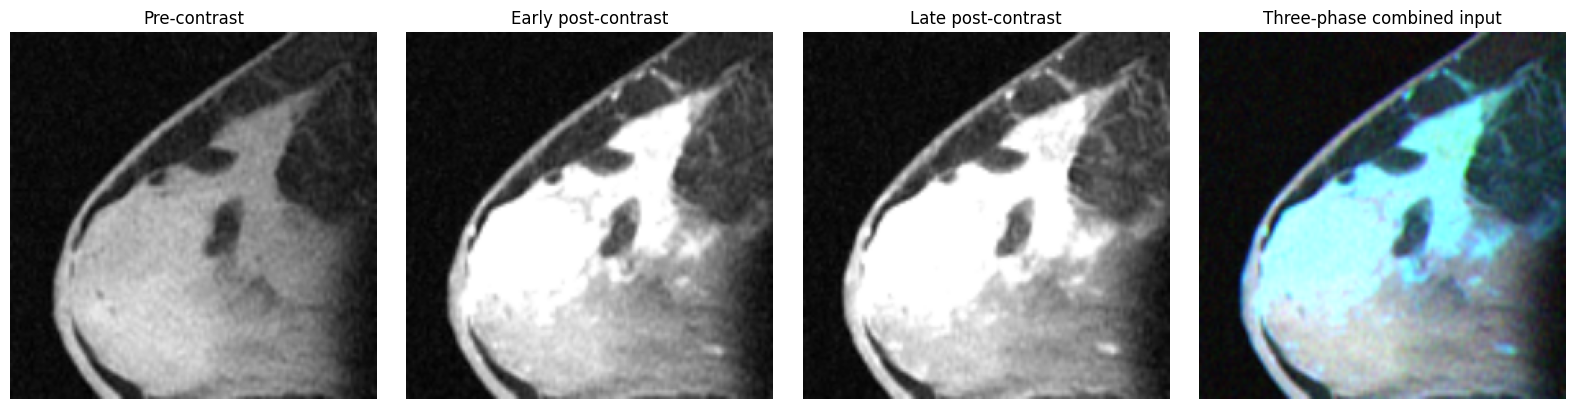

In [11]:

# ==========================================
# SECTION 8 — VISUALIZE PROCESSED INPUT
# ==========================================

middle = len(sample_images) // 2

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

channel_names = [
    "Pre-contrast",
    "Early post-contrast",
    "Late post-contrast"
]

for i in range(3):
    axes[i].imshow(
        sample_images[middle, i].numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[i].set_title(channel_names[i])
    axes[i].axis("off")

# Combine three channels for a colour visualization
rgb = sample_images[middle].permute(1, 2, 0).numpy()

axes[3].imshow(rgb)
axes[3].set_title("Three-phase combined input")
axes[3].axis("off")

plt.tight_layout()
plt.show()


In [12]:

# ==========================================
# SECTION 9 — PROCESS TRAINING PATIENTS
# ==========================================

import os
import re
import torch
import nibabel as nib
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from pathlib import Path

# Save processed MRI crops in Google Drive
CROP_DIR = BASE_PATH / "processed_vitmae" / "train"
CROP_DIR.mkdir(parents=True, exist_ok=True)

train_patients = master[
    master["split"].astype(str).str.lower() == "train"
].copy()

print("Training patients:", len(train_patients))
print("Patients with missing pCR in training:",
      train_patients["pCR"].isna().sum())

records = []
failed_patients = []

for _, row in tqdm(
    train_patients.iterrows(),
    total=len(train_patients),
    desc="Processing training MRIs"
):
    pid = str(row["pid"])
    safe_pid = re.sub(r"[^A-Za-z0-9_-]", "_", pid)

    output_path = CROP_DIR / f"{safe_pid}.pt"

    try:
        # Load all four volumes
        patient_volumes = {}

        columns = {
            "Pre-contrast": "dce_0",
            "Early post-contrast": "dce_1",
            "Late post-contrast": "dce_2",
            "Tumour mask": "mask"
        }

        for name, column in columns.items():
            path = resolve_path(row[column])

            if path is None:
                raise FileNotFoundError(
                    f"Could not find {column}: {row[column]}"
                )

            nii = nib.load(str(path))
            patient_volumes[name] = nii.get_fdata(
                dtype=np.float32
            )

        # Extract tumour-centred slices
        crops, slice_indices = create_patient_crops(
            patient_volumes
        )

        # Save as float16 to reduce storage
        torch.save(
            {
                "pid": pid,
                "images": crops.half(),
                "slice_indices": slice_indices
            },
            output_path
        )

        records.append({
            "pid": pid,
            "file": str(output_path),
            "num_slices": len(slice_indices),
            "pCR": row["pCR"]
        })

    except Exception as e:
        failed_patients.append({
            "pid": pid,
            "error": str(e)
        })

# Save processing manifest
manifest = pd.DataFrame(records)

manifest_path = CROP_DIR / "train_manifest.csv"
manifest.to_csv(manifest_path, index=False)

print("\n========== PROCESSING SUMMARY ==========")
print("Successfully processed:", len(records))
print("Failed:", len(failed_patients))
print("Total extracted slices:", manifest["num_slices"].sum()
      if len(manifest) else 0)
print("Manifest:", manifest_path)

if failed_patients:
    print("\nFailed patients:")
    print(pd.DataFrame(failed_patients).to_string(index=False))

if len(records) != len(train_patients):
    raise RuntimeError(
        "Not all training patients were processed. "
        "Resolve the failures before training."
    )


Training patients: 120
Patients with missing pCR in training: 1


Processing training MRIs:   0%|          | 0/120 [00:00<?, ?it/s]


========== PROCESSING SUMMARY ==========
Successfully processed: 120
Failed: 0
Total extracted slices: 3162
Manifest: /content/drive/MyDrive/Breast_Cancer_AI_Project/processed_vitmae/train/train_manifest.csv


In [13]:

# ==========================================
# CHECK EXISTING NNU-NET PREDICTIONS
# ==========================================

from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/Breast_Cancer_AI_Project"
)

folders = {
    "Model checkpoints": (
        BASE / "nnUNet_results" /
        "Dataset001_BreastDCEDL" /
        "nnUNetTrainer__nnUNetPlans__3d_fullres"
    ),

    "Validation predictions": (
        BASE / "inference" /
        "validation" / "probabilities"
    ),

    "Test predictions": (
        BASE / "inference" /
        "test" / "probabilities"
    ),

    "Old validation predictions": Path(
        "/content/validation_probabilities"
    ),

    "Old ensemble predictions": Path(
        "/content/predictions_ensemble"
    )
}

for name, folder in folders.items():

    print("\n" + "=" * 60)
    print(name)
    print("Path:", folder)
    print("Exists:", folder.exists())

    if folder.exists():

        nii_files = list(folder.glob("*.nii.gz"))
        npz_files = list(folder.glob("*.npz"))
        checkpoints = list(folder.glob("checkpoint*.pth"))

        print("NIfTI masks:", len(nii_files))
        print("Probability files:", len(npz_files))
        print("Checkpoints:", len(checkpoints))

        print("\nFirst 5 files:")

        for f in sorted(folder.iterdir())[:5]:
            print(" ", f.name)



Model checkpoints
Path: /content/drive/MyDrive/Breast_Cancer_AI_Project/nnUNet_results/Dataset001_BreastDCEDL/nnUNetTrainer__nnUNetPlans__3d_fullres
Exists: True
NIfTI masks: 0
Probability files: 0
Checkpoints: 0

First 5 files:
  dataset.json
  dataset_fingerprint.json
  fold_0
  fold_1
  fold_2

Validation predictions
Path: /content/drive/MyDrive/Breast_Cancer_AI_Project/inference/validation/probabilities
Exists: True
NIfTI masks: 26
Probability files: 26
Checkpoints: 0

First 5 files:
  ISPY1_1002.nii.gz
  ISPY1_1002.npz
  ISPY1_1002.pkl
  ISPY1_1003.nii.gz
  ISPY1_1003.npz

Test predictions
Path: /content/drive/MyDrive/Breast_Cancer_AI_Project/inference/test/probabilities
Exists: True
NIfTI masks: 26
Probability files: 26
Checkpoints: 0

First 5 files:
  ISPY1_1029.nii.gz
  ISPY1_1029.npz
  ISPY1_1029.pkl
  ISPY1_1070.nii.gz
  ISPY1_1070.npz

Old validation predictions
Path: /content/validation_probabilities
Exists: False

Old ensemble predictions
Path: /content/predictions_ensemb

In [14]:

from pathlib import Path
import json

BASE = Path(
    "/content/drive/MyDrive/Breast_Cancer_AI_Project"
)

# ------------------------------------------------
# A. CHECK ALL FIVE MODEL FOLDS
# ------------------------------------------------

MODEL_DIR = (
    BASE / "nnUNet_results" /
    "Dataset001_BreastDCEDL" /
    "nnUNetTrainer__nnUNetPlans__3d_fullres"
)

print("=" * 65)
print("CHECKPOINT AUDIT")
print("=" * 65)

for fold in range(5):

    fold_dir = MODEL_DIR / f"fold_{fold}"

    print(f"\nFold {fold}:")
    print("Folder exists:", fold_dir.exists())

    if fold_dir.exists():

        for file in sorted(fold_dir.iterdir()):
            if file.is_file():
                size_mb = file.stat().st_size / (1024 ** 2)
                print(f"  {file.name}: {size_mb:.2f} MB")


# ------------------------------------------------
# B. SEARCH FOR EXISTING TRAINING PREDICTIONS
# ------------------------------------------------

print("\n" + "=" * 65)
print("SEARCHING FOR TRAINING PREDICTIONS")
print("=" * 65)

search_dirs = [
    BASE / "inference",
    BASE / "predictions",
    BASE / "visualizations",
    BASE / "nnUNet_raw"
]

for directory in search_dirs:

    print(f"\nDirectory: {directory}")

    if not directory.exists():
        print("Not found")
        continue

    for file in directory.rglob("*.nii.gz"):
        print(" ", file.relative_to(BASE))


# ------------------------------------------------
# C. CHECK SAVED FOLD ASSIGNMENTS
# ------------------------------------------------

print("\n" + "=" * 65)
print("CHECKING FOLD ASSIGNMENTS")
print("=" * 65)

split_paths = [
    BASE / "nnUNet_raw" /
    "Dataset001_BreastDCEDL" / "splits_final.json",

    BASE / "nnUNet_preprocessed" /
    "Dataset001_BreastDCEDL" / "splits_final.json"
]

for split_path in split_paths:

    print("\nPath:", split_path)
    print("Exists:", split_path.exists())

    if split_path.exists():

        with open(split_path) as f:
            splits = json.load(f)

        print("Number of folds:", len(splits))

        for i, split in enumerate(splits):
            print(
                f"Fold {i}: "
                f"train={len(split['train'])}, "
                f"validation={len(split['val'])}"
            )


CHECKPOINT AUDIT

Fold 0:
Folder exists: True
  checkpoint_best.pth: 341.17 MB
  debug.json: 0.02 MB
  progress.png: 0.64 MB
  training_log_2026_9_10_19_24_11.txt: 0.02 MB

Fold 1:
Folder exists: True
  checkpoint_best.pth: 341.16 MB
  debug.json: 0.02 MB
  progress.png: 0.51 MB
  training_log_2026_9_11_00_20_31.txt: 0.01 MB

Fold 2:
Folder exists: True
  checkpoint_best.pth: 341.17 MB
  debug.json: 0.02 MB
  progress.png: 0.55 MB
  training_log_2026_9_11_03_03_12.txt: 0.02 MB

Fold 3:
Folder exists: True
  checkpoint_best.pth: 341.16 MB
  debug.json: 0.02 MB
  progress.png: 0.50 MB
  training_log_2026_9_11_06_34_36.txt: 0.01 MB

Fold 4:
Folder exists: True
  checkpoint_best.pth: 341.16 MB
  debug.json: 0.02 MB
  progress.png: 0.53 MB
  training_log_2026_9_11_10_53_50.txt: 0.01 MB

SEARCHING FOR TRAINING PREDICTIONS

Directory: /content/drive/MyDrive/Breast_Cancer_AI_Project/inference
  inference/test/images/ISPY1_1177_0002.nii.gz
  inference/test/images/ISPY1_1177_0001.nii.gz
  infere

In [15]:
import json
from pathlib import Path

BASE = Path("/content/drive/MyDrive/Breast_Cancer_AI_Project")

DATASET_DIR = (
    BASE / "nnUNet_raw" /
    "Dataset001_BreastDCEDL"
)

SPLIT_FILE = DATASET_DIR / "splits_final.json"
IMAGES_DIR = DATASET_DIR / "imagesTr"

with open(SPLIT_FILE) as f:
    splits = json.load(f)

# Get the actual training case names
available_cases = sorted({
    p.name.replace("_0000.nii.gz", "")
    for p in IMAGES_DIR.glob("*_0000.nii.gz")
})

print("Training image cases:", len(available_cases))
print("Fold assignments:", len(splits))

for fold_idx, fold in enumerate(splits):
    val_cases = fold["val"]

    print(f"\nFold {fold_idx}")
    print("Validation cases:", len(val_cases))
    print("First 5:", val_cases[:5])

    missing = set(val_cases) - set(available_cases)
    print("Missing from imagesTr:", len(missing))

    if missing:
        print("Examples:", list(missing)[:5])

print("\nCheckpoint verification:")
MODEL_DIR = (
    BASE / "nnUNet_results" /
    "Dataset001_BreastDCEDL" /
    "nnUNetTrainer__nnUNetPlans__3d_fullres"
)

for i in range(5):
    checkpoint = MODEL_DIR / f"fold_{i}" / "checkpoint_best.pth"
    print(f"Fold {i}: {checkpoint.exists()}")

Training image cases: 120
Fold assignments: 5

Fold 0
Validation cases: 24
First 5: ['ISPY1_1008', 'ISPY1_1013', 'ISPY1_1030', 'ISPY1_1034', 'ISPY1_1049']
Missing from imagesTr: 0

Fold 1
Validation cases: 24
First 5: ['ISPY1_1005', 'ISPY1_1010', 'ISPY1_1012', 'ISPY1_1021', 'ISPY1_1035']
Missing from imagesTr: 0

Fold 2
Validation cases: 24
First 5: ['ISPY1_1001', 'ISPY1_1031', 'ISPY1_1032', 'ISPY1_1036', 'ISPY1_1040']
Missing from imagesTr: 0

Fold 3
Validation cases: 24
First 5: ['ISPY1_1007', 'ISPY1_1009', 'ISPY1_1017', 'ISPY1_1027', 'ISPY1_1042']
Missing from imagesTr: 0

Fold 4
Validation cases: 24
First 5: ['ISPY1_1004', 'ISPY1_1011', 'ISPY1_1015', 'ISPY1_1016', 'ISPY1_1025']
Missing from imagesTr: 0

Checkpoint verification:
Fold 0: True
Fold 1: True
Fold 2: True
Fold 3: True
Fold 4: True


In [17]:
import os
import shutil
from pathlib import Path

BASE = Path("/content/drive/MyDrive/Breast_Cancer_AI_Project")

DATASET_DIR = BASE / "nnUNet_raw" / "Dataset001_BreastDCEDL"

MODEL_DIR = (
    BASE / "nnUNet_results" /
    "Dataset001_BreastDCEDL" /
    "nnUNetTrainer__nnUNetPlans__3d_fullres"
)

# Set the two paths needed for this prediction setup
os.environ["nnUNet_raw"] = str(BASE / "nnUNet_raw")
os.environ["nnUNet_results"] = str(BASE / "nnUNet_results")

# Do not require nnUNet_preprocessed for this inference check.
# We will use the trained model's saved plans and checkpoints.

print("nnUNet_raw:", os.environ["nnUNet_raw"])
print("nnUNet_results:", os.environ["nnUNet_results"])
print("nnUNetv2_predict:", shutil.which("nnUNetv2_predict"))

print("\nDataset JSON exists:", (DATASET_DIR / "dataset.json").exists())

for i in range(5):
    fold_dir = MODEL_DIR / f"fold_{i}"
    print(f"\nFold {i}")
    print("Checkpoint:", (fold_dir / "checkpoint_best.pth").exists())
    print("Plans:", (fold_dir / "plans.json").exists())

nnUNet_raw: /content/drive/MyDrive/Breast_Cancer_AI_Project/nnUNet_raw
nnUNet_results: /content/drive/MyDrive/Breast_Cancer_AI_Project/nnUNet_results
nnUNetv2_predict: None

Dataset JSON exists: True

Fold 0
Checkpoint: True
Plans: False

Fold 1
Checkpoint: True
Plans: False

Fold 2
Checkpoint: True
Plans: False

Fold 3
Checkpoint: True
Plans: False

Fold 4
Checkpoint: True
Plans: False


In [18]:
import os
import sys
import importlib.util
import subprocess
from pathlib import Path

BASE = Path("/content/drive/MyDrive/Breast_Cancer_AI_Project")

MODEL_DIR = (
    BASE / "nnUNet_results" /
    "Dataset001_BreastDCEDL" /
    "nnUNetTrainer__nnUNetPlans__3d_fullres"
)

print("===== NNUNET INSTALLATION =====")

print("Python:", sys.executable)
print("nnunetv2 module:", importlib.util.find_spec("nnunetv2"))
print("nnUNetv2_predict command:", subprocess.run(
    ["bash", "-lc", "which nnUNetv2_predict"],
    capture_output=True, text=True
).stdout.strip() or "Not found")

print("\n===== MODEL DIRECTORY =====")

for name in ["plans.json", "dataset.json", "dataset_fingerprint.json"]:
    path = MODEL_DIR / name
    print(name, ":", path.exists())

print("\n===== MODEL DIRECTORY FILES =====")

for path in sorted(MODEL_DIR.iterdir()):
    print(path.name)

print("\n===== FOLD 0 FILES =====")

for path in sorted((MODEL_DIR / "fold_0").iterdir()):
    print(path.name)

===== NNUNET INSTALLATION =====
Python: /usr/bin/python3
nnunetv2 module: None
nnUNetv2_predict command: Not found

===== MODEL DIRECTORY =====
plans.json : True
dataset.json : True
dataset_fingerprint.json : True

===== MODEL DIRECTORY FILES =====
dataset.json
dataset_fingerprint.json
fold_0
fold_1
fold_2
fold_3
fold_4
plans.json

===== FOLD 0 FILES =====
checkpoint_best.pth
debug.json
progress.png
training_log_2026_9_10_19_24_11.txt


In [19]:
!pip install -q nnunetv2

In [20]:
import torch
import shutil
import nnunetv2

print("nnU-Net module:", nnunetv2.__file__)
print("Prediction command:", shutil.which("nnUNetv2_predict"))

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

nnU-Net module: /usr/local/lib/python3.13/dist-packages/nnunetv2/__init__.py
Prediction command: /usr/local/bin/nnUNetv2_predict
PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [21]:
import os
import json
import shutil
from pathlib import Path

BASE = Path("/content/drive/MyDrive/Breast_Cancer_AI_Project")

DATASET_DIR = BASE / "nnUNet_raw" / "Dataset001_BreastDCEDL"

MODEL_DIR = (
    BASE / "nnUNet_results" /
    "Dataset001_BreastDCEDL" /
    "nnUNetTrainer__nnUNetPlans__3d_fullres"
)

OOF_DIR = BASE / "inference" / "oof"
INPUT_ROOT = Path("/content/oof_inputs")

os.environ["nnUNet_raw"] = str(BASE / "nnUNet_raw")
os.environ["nnUNet_results"] = str(BASE / "nnUNet_results")

predict_executable = shutil.which("nnUNetv2_predict")
assert predict_executable, "nnUNetv2_predict is not installed."

with open(DATASET_DIR / "splits_final.json") as f:
    splits = json.load(f)

assert len(splits) == 5

for i, fold in enumerate(splits):
    checkpoint = MODEL_DIR / f"fold_{i}" / "checkpoint_best.pth"
    assert checkpoint.exists(), f"Missing checkpoint: {checkpoint}"

    for case in fold["val"]:
        for channel in range(3):
            image = DATASET_DIR / "imagesTr" / f"{case}_{channel:04d}.nii.gz"
            assert image.exists(), f"Missing image: {image}"

print("All five checkpoints verified.")
print("All 120 patients and their three DCE channels verified.")
print("Prediction executable:", predict_executable)
print("Output directory:", OOF_DIR)

All five checkpoints verified.
All 120 patients and their three DCE channels verified.
Prediction executable: /usr/local/bin/nnUNetv2_predict
Output directory: /content/drive/MyDrive/Breast_Cancer_AI_Project/inference/oof


In [22]:
import subprocess

fold_idx = 0
fold = splits[fold_idx]

input_dir = INPUT_ROOT / f"fold_{fold_idx}"
output_dir = OOF_DIR / f"fold_{fold_idx}" / "predictions"

input_dir.mkdir(parents=True, exist_ok=True)
output_dir.mkdir(parents=True, exist_ok=True)

# Prepare only the 24 held-out patients for fold 0
for case in fold["val"]:
    for channel in range(3):
        filename = f"{case}_{channel:04d}.nii.gz"
        source = DATASET_DIR / "imagesTr" / filename
        destination = input_dir / filename

        if not destination.exists():
            destination.symlink_to(source)

# Do not overwrite an existing prediction folder
if any(output_dir.iterdir()):
    raise RuntimeError(
        f"{output_dir} is not empty. Inspect it before running inference."
    )

command = [
    predict_executable,
    "-i", str(input_dir),
    "-o", str(output_dir),
    "-d", "1",
    "-c", "3d_fullres",
    "-f", "0",
    "-tr", "nnUNetTrainer",
    "-chk", "checkpoint_best.pth",
    "--save_probabilities",
    "-device", "cuda"
]

print("Starting Fold 0 inference for", len(fold["val"]), "patients.")

result = subprocess.run(
    command,
    env=os.environ.copy(),
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT
)

print(result.stdout[-6000:])

if result.returncode != 0:
    raise RuntimeError("Fold 0 inference failed. Inspect the log above.")

masks = list(output_dir.glob("*.nii.gz"))
probabilities = list(output_dir.glob("*.npz"))

print("\nFold 0 completed.")
print("Masks:", len(masks))
print("Probability files:", len(probabilities))

Starting Fold 0 inference for 24 patients.
Y1_1051:
perform_everything_on_device: True

100%|██████████| 2/2 [00:02<00:00,  1.02s/it]
sending off prediction to background worker for resampling and export
done with ISPY1_1051

Predicting ISPY1_1056:
perform_everything_on_device: True

100%|██████████| 2/2 [00:02<00:00,  1.01s/it]
sending off prediction to background worker for resampling and export
done with ISPY1_1056

Predicting ISPY1_1069:
perform_everything_on_device: True

100%|██████████| 1/1 [00:00<00:00,  1.28it/s]
sending off prediction to background worker for resampling and export
done with ISPY1_1069

Predicting ISPY1_1090:
perform_everything_on_device: True

100%|██████████| 1/1 [00:00<00:00,  1.30it/s]
sending off prediction to background worker for resampling and export
done with ISPY1_1090

Predicting ISPY1_1097:
perform_everything_on_device: True

100%|██████████| 1/1 [00:00<00:00,  1.33it/s]
sending off prediction to background worker for resampling and export
done wit

In [23]:
import subprocess
from pathlib import Path

for fold_idx in range(1, 5):

    fold = splits[fold_idx]

    input_dir = INPUT_ROOT / f"fold_{fold_idx}"
    output_dir = OOF_DIR / f"fold_{fold_idx}" / "predictions"

    input_dir.mkdir(parents=True, exist_ok=True)
    output_dir.mkdir(parents=True, exist_ok=True)

    # Prepare the held-out patients for this fold
    for case in fold["val"]:
        for channel in range(3):
            filename = f"{case}_{channel:04d}.nii.gz"
            source = DATASET_DIR / "imagesTr" / filename
            destination = input_dir / filename

            if not destination.exists():
                destination.symlink_to(source)

    # Protect existing predictions
    if any(output_dir.iterdir()):
        raise RuntimeError(
            f"Fold {fold_idx} output is not empty. Inspect it before proceeding."
        )

    command = [
        predict_executable,
        "-i", str(input_dir),
        "-o", str(output_dir),
        "-d", "1",
        "-c", "3d_fullres",
        "-f", str(fold_idx),
        "-tr", "nnUNetTrainer",
        "-chk", "checkpoint_best.pth",
        "--save_probabilities",
        "-device", "cuda"
    ]

    print(f"\n{'='*50}")
    print(f"Starting Fold {fold_idx}: {len(fold['val'])} patients")
    print(f"{'='*50}")

    result = subprocess.run(
        command,
        env=os.environ.copy(),
        text=True,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT
    )

    print(result.stdout[-4000:])

    if result.returncode != 0:
        raise RuntimeError(f"Fold {fold_idx} inference failed.")

    masks = list(output_dir.glob("*.nii.gz"))
    probabilities = list(output_dir.glob("*.npz"))

    print(f"Fold {fold_idx} masks: {len(masks)}")
    print(f"Fold {fold_idx} probability files: {len(probabilities)}")

    if len(masks) != 24 or len(probabilities) != 24:
        raise RuntimeError(f"Fold {fold_idx} output count is incorrect.")

print("\nAll remaining folds completed successfully!")


Starting Fold 1: 24 patients
ending off prediction to background worker for resampling and export
done with ISPY1_1100

Predicting ISPY1_1112:
perform_everything_on_device: True

100%|██████████| 1/1 [00:00<00:00,  1.25it/s]
sending off prediction to background worker for resampling and export
done with ISPY1_1112

Predicting ISPY1_1127:
perform_everything_on_device: True

100%|██████████| 2/2 [00:01<00:00,  1.00it/s]
sending off prediction to background worker for resampling and export
done with ISPY1_1127

Predicting ISPY1_1145:
perform_everything_on_device: True

100%|██████████| 3/3 [00:03<00:00,  1.04s/it]
sending off prediction to background worker for resampling and export
done with ISPY1_1145

Predicting ISPY1_1147:
perform_everything_on_device: True

100%|██████████| 2/2 [00:01<00:00,  1.06it/s]
sending off prediction to background worker for resampling and export
done with ISPY1_1147

Predicting ISPY1_1149:
perform_everything_on_device: True

100%|██████████| 1/1 [00:00<00:0

In [24]:
total_masks = 0
total_probabilities = 0
all_cases = []

for fold_idx in range(5):

    output_dir = OOF_DIR / f"fold_{fold_idx}" / "predictions"

    masks = list(output_dir.glob("*.nii.gz"))
    probabilities = list(output_dir.glob("*.npz"))

    total_masks += len(masks)
    total_probabilities += len(probabilities)

    all_cases.extend([p.stem for p in masks])

    print(
        f"Fold {fold_idx}: "
        f"{len(masks)} masks | "
        f"{len(probabilities)} probability files"
    )

print("\nTOTAL MASKS:", total_masks)
print("TOTAL PROBABILITY FILES:", total_probabilities)
print("UNIQUE PATIENTS:", len(set(all_cases)))

assert total_masks == 120
assert total_probabilities == 120
assert len(set(all_cases)) == 120

print("\nOOF PREDICTION VERIFICATION PASSED!")

Fold 0: 24 masks | 24 probability files
Fold 1: 24 masks | 24 probability files
Fold 2: 24 masks | 24 probability files
Fold 3: 24 masks | 24 probability files
Fold 4: 24 masks | 24 probability files

TOTAL MASKS: 120
TOTAL PROBABILITY FILES: 120
UNIQUE PATIENTS: 120

OOF PREDICTION VERIFICATION PASSED!


In [25]:
import nibabel as nib
import numpy as np
import json
from pathlib import Path

with open(DATASET_DIR / "splits_final.json") as f:
    splits = json.load(f)

# Select one patient from each fold
for fold_idx in range(5):

    case = splits[fold_idx]["val"][0]

    image_path = DATASET_DIR / "imagesTr" / f"{case}_0000.nii.gz"

    mask_path = (
        OOF_DIR / f"fold_{fold_idx}" /
        "predictions" / f"{case}.nii.gz"
    )

    image = nib.load(str(image_path))
    mask = nib.load(str(mask_path))

    image_data = image.get_fdata()
    mask_data = mask.get_fdata()

    print(f"\nFold {fold_idx} | Patient: {case}")
    print("Image shape:", image_data.shape)
    print("Mask shape:", mask_data.shape)
    print("Same shape:", image_data.shape == mask_data.shape)
    print("Same affine:", np.allclose(image.affine, mask.affine))
    print("Mask labels:", np.unique(mask_data))
    print("Tumour voxels:", int(np.sum(mask_data > 0)))

    assert image_data.shape == mask_data.shape
    assert np.allclose(image.affine, mask.affine)
    assert np.sum(mask_data > 0) > 0

print("\nInitial MRI-mask alignment checks passed.")


Fold 0 | Patient: ISPY1_1008
Image shape: (28, 256, 256)
Mask shape: (28, 256, 256)
Same shape: True
Same affine: True
Mask labels: [0. 1.]
Tumour voxels: 3809

Fold 1 | Patient: ISPY1_1005
Image shape: (43, 256, 256)
Mask shape: (43, 256, 256)
Same shape: True
Same affine: True
Mask labels: [0. 1.]
Tumour voxels: 42723

Fold 2 | Patient: ISPY1_1001
Image shape: (30, 256, 256)
Mask shape: (30, 256, 256)
Same shape: True
Same affine: True
Mask labels: [0. 1.]
Tumour voxels: 26590

Fold 3 | Patient: ISPY1_1007
Image shape: (24, 256, 256)
Mask shape: (24, 256, 256)
Same shape: True
Same affine: True
Mask labels: [0. 1.]
Tumour voxels: 5475

Fold 4 | Patient: ISPY1_1004
Image shape: (45, 256, 256)
Mask shape: (45, 256, 256)
Same shape: True
Same affine: True
Mask labels: [0. 1.]
Tumour voxels: 73640

Initial MRI-mask alignment checks passed.


Patient: ISPY1_1008
DCE channel 0: (28, 256, 256)
DCE channel 1: (28, 256, 256)
DCE channel 2: (28, 256, 256)
Mask: (28, 256, 256)
Tumour voxels: 3809
Tumour-containing slices: [ 2  3  4  5  6 10 13 14 15 16 17 18 19 20 21 22 23 24 25]
Number of tumour slices: 19


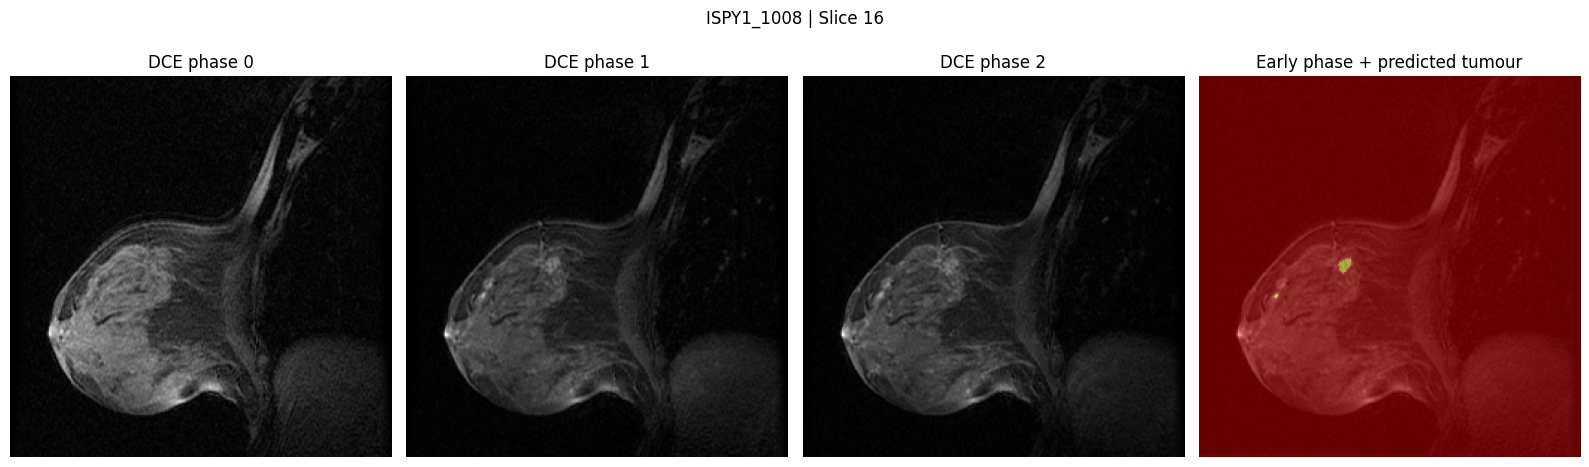

In [26]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

fold_idx = 0
case = splits[fold_idx]["val"][0]

# Load all three DCE phases
volumes = []

for channel in range(3):
    path = DATASET_DIR / "imagesTr" / f"{case}_{channel:04d}.nii.gz"
    volumes.append(nib.load(str(path)).get_fdata().astype(np.float32))

# Load OOF predicted mask
mask_path = (
    OOF_DIR / f"fold_{fold_idx}" /
    "predictions" / f"{case}.nii.gz"
)
mask = nib.load(str(mask_path)).get_fdata() > 0

print("Patient:", case)
for i, volume in enumerate(volumes):
    print(f"DCE channel {i}: {volume.shape}")

print("Mask:", mask.shape)
print("Tumour voxels:", mask.sum())

# Find slices containing tumour
tumour_slices = np.where(mask.sum(axis=(1, 2)) > 0)[0]

print("Tumour-containing slices:", tumour_slices)
print("Number of tumour slices:", len(tumour_slices))

# Display the middle tumour-containing slice
slice_idx = tumour_slices[len(tumour_slices) // 2]

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for i in range(3):
    axes[i].imshow(volumes[i][slice_idx], cmap="gray")
    axes[i].set_title(f"DCE phase {i}")
    axes[i].axis("off")

axes[3].imshow(volumes[1][slice_idx], cmap="gray")
axes[3].imshow(mask[slice_idx], cmap="autumn", alpha=0.4)
axes[3].set_title("Early phase + predicted tumour")
axes[3].axis("off")

plt.suptitle(f"{case} | Slice {slice_idx}")
plt.tight_layout()
plt.show()

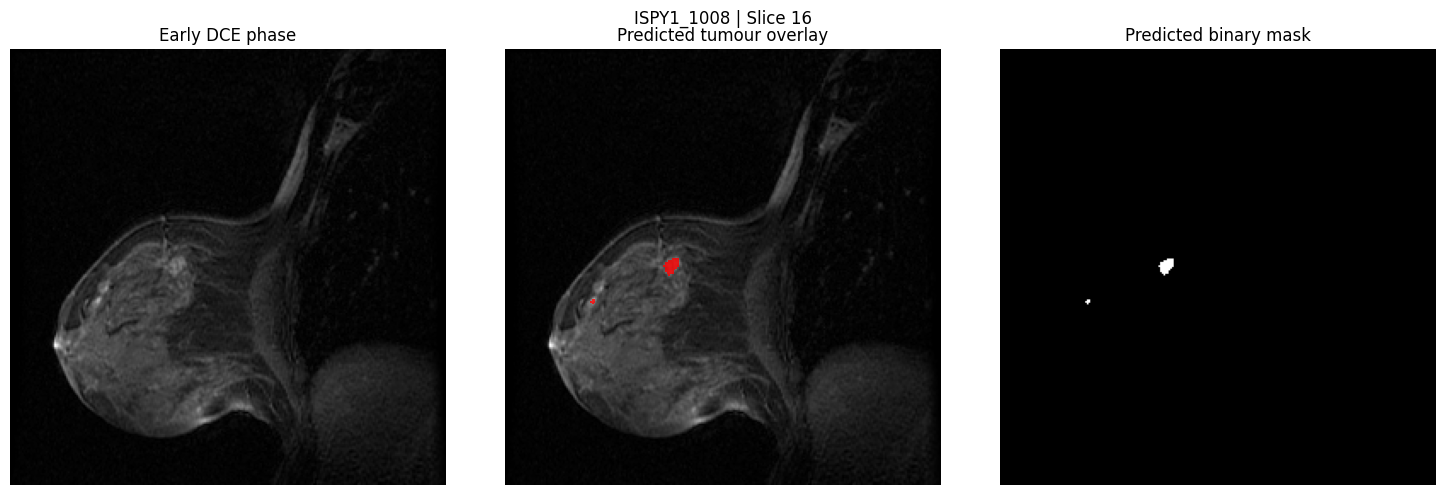

Tumour bounding box:
X: 50 to 101
Y: 123 to 149
Tumour pixels on this slice: 64


In [27]:
import numpy as np
import matplotlib.pyplot as plt

# Use the same patient and slice
slice_idx = tumour_slices[len(tumour_slices) // 2]

early_phase = volumes[1][slice_idx]
tumour_slice = mask[slice_idx]

# Make background pixels transparent
tumour_overlay = np.ma.masked_where(
    tumour_slice == 0,
    tumour_slice
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(early_phase, cmap="gray")
axes[0].set_title("Early DCE phase")

axes[1].imshow(early_phase, cmap="gray")
axes[1].imshow(
    tumour_overlay,
    cmap="autumn",
    alpha=0.8,
    interpolation="nearest"
)
axes[1].set_title("Predicted tumour overlay")

axes[2].imshow(tumour_slice, cmap="gray")
axes[2].set_title("Predicted binary mask")

for ax in axes:
    ax.axis("off")

plt.suptitle(f"{case} | Slice {slice_idx}")
plt.tight_layout()
plt.show()

# Bounding box of tumour on this slice
coords = np.argwhere(tumour_slice)

if len(coords):
    y_min, x_min = coords.min(axis=0)
    y_max, x_max = coords.max(axis=0)

    print("Tumour bounding box:")
    print("X:", x_min, "to", x_max)
    print("Y:", y_min, "to", y_max)
    print("Tumour pixels on this slice:", len(coords))

3D tumour bounding box:
Z: 2 to 25
Y: 112 to 198
X: 50 to 116
Crop centre: 155 83
Crop array shape: (19, 224, 224, 3)
Expected: (number of tumour slices, 224, 224, 3)
Value range: 0.0 1.0


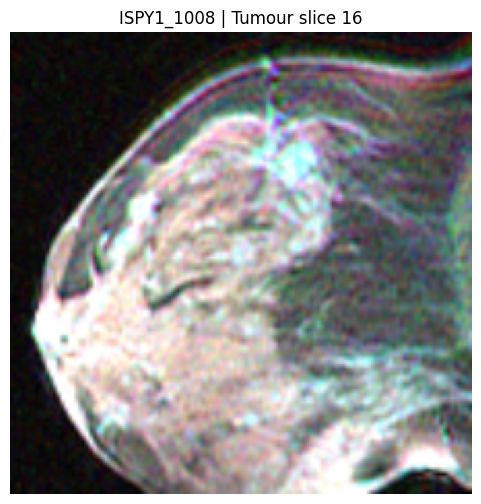

In [28]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

CROP_SIZE = 128
OUTPUT_SIZE = 224

# Find all tumour coordinates in 3D
coords = np.argwhere(mask)

assert len(coords) > 0, "Empty tumour mask!"

# Bounding box and centre
z_min, y_min, x_min = coords.min(axis=0)
z_max, y_max, x_max = coords.max(axis=0)

center_y = (y_min + y_max) // 2
center_x = (x_min + x_max) // 2

print("3D tumour bounding box:")
print("Z:", z_min, "to", z_max)
print("Y:", y_min, "to", y_max)
print("X:", x_min, "to", x_max)
print("Crop centre:", center_y, center_x)

# Fixed-size crop around the tumour centre
half = CROP_SIZE // 2

y1 = center_y - half
y2 = center_y + half
x1 = center_x - half
x2 = center_x + half

# Normalize each DCE phase independently using robust percentiles
normalized_volumes = []

for volume in volumes:
    low, high = np.percentile(volume, [1, 99])

    normalized = np.clip(
        (volume - low) / (high - low + 1e-8),
        0, 1
    )

    normalized_volumes.append(normalized)

# Extract tumour-containing slices
tumour_slices = np.where(mask.sum(axis=(1, 2)) > 0)[0]

sample_crops = []

for z in tumour_slices:

    channels = []

    for volume in normalized_volumes:

        padded = np.pad(
            volume[z],
            ((half, half), (half, half)),
            mode="constant"
        )

        crop = padded[
            y1 + half:y2 + half,
            x1 + half:x2 + half
        ]

        crop = cv2.resize(
            crop,
            (OUTPUT_SIZE, OUTPUT_SIZE),
            interpolation=cv2.INTER_LINEAR
        )

        channels.append(crop)

    # H x W x 3
    rgb_crop = np.stack(channels, axis=-1)
    sample_crops.append(rgb_crop)

sample_crops = np.asarray(sample_crops, dtype=np.float32)

print("Crop array shape:", sample_crops.shape)
print("Expected:", "(number of tumour slices, 224, 224, 3)")
print("Value range:", sample_crops.min(), sample_crops.max())

# Visualize the middle crop
mid = len(sample_crops) // 2

plt.figure(figsize=(6, 6))
plt.imshow(sample_crops[mid])
plt.title(f"{case} | Tumour slice {tumour_slices[mid]}")
plt.axis("off")
plt.show()

In [29]:
import cv2
import numpy as np
import pandas as pd
import nibabel as nib
from pathlib import Path
from tqdm.auto import tqdm

CROP_SIZE = 128
OUTPUT_SIZE = 224

CROP_DIR = BASE / "data" / "vit_mae_crops"
CROP_DIR.mkdir(parents=True, exist_ok=True)

metadata = []
failed_cases = []

def extract_patient_crops(fold_idx, case):

    # Load three DCE phases
    volumes = []

    for channel in range(3):
        path = DATASET_DIR / "imagesTr" / f"{case}_{channel:04d}.nii.gz"
        volume = nib.load(str(path)).get_fdata().astype(np.float32)
        volumes.append(volume)

    # Load OOF predicted segmentation
    mask_path = (
        OOF_DIR / f"fold_{fold_idx}" /
        "predictions" / f"{case}.nii.gz"
    )

    mask = nib.load(str(mask_path)).get_fdata() > 0

    # Validate alignment
    assert all(v.shape == mask.shape for v in volumes), case

    coords = np.argwhere(mask)

    if len(coords) == 0:
        raise ValueError(f"Empty predicted tumour mask: {case}")

    # 3D tumour centre
    _, y_min, x_min = coords.min(axis=0)
    _, y_max, x_max = coords.max(axis=0)

    center_y = (y_min + y_max) // 2
    center_x = (x_min + x_max) // 2

    half = CROP_SIZE // 2

    y1, y2 = center_y - half, center_y + half
    x1, x2 = center_x - half, center_x + half

    # Normalize each phase using its 1st and 99th percentiles
    normalized_volumes = []

    for volume in volumes:
        low, high = np.percentile(volume, [1, 99])

        normalized = np.clip(
            (volume - low) / (high - low + 1e-8),
            0, 1
        )

        normalized_volumes.append(normalized)

    # Select slices containing predicted tumour
    tumour_slices = np.where(mask.sum(axis=(1, 2)) > 0)[0]

    patient_crops = []

    for z in tumour_slices:

        channels = []

        for volume in normalized_volumes:

            padded = np.pad(
                volume[z],
                ((half, half), (half, half)),
                mode="constant"
            )

            crop = padded[
                y1 + half:y2 + half,
                x1 + half:x2 + half
            ]

            crop = cv2.resize(
                crop,
                (OUTPUT_SIZE, OUTPUT_SIZE),
                interpolation=cv2.INTER_LINEAR
            )

            channels.append(crop)

        crop_3channel = np.stack(channels, axis=-1)

        # Store as uint8 to reduce storage
        crop_3channel = np.round(
            crop_3channel * 255
        ).astype(np.uint8)

        patient_crops.append(crop_3channel)

    patient_crops = np.stack(patient_crops)

    return patient_crops, tumour_slices


# Process all five folds
for fold_idx, fold in enumerate(splits):

    for case in tqdm(fold["val"], desc=f"Fold {fold_idx}"):

        try:
            crops, slice_indices = extract_patient_crops(
                fold_idx, case
            )

            output_path = CROP_DIR / f"{case}.npz"

            np.savez_compressed(
                output_path,
                crops=crops,
                slice_indices=slice_indices
            )

            metadata.append({
                "patient_id": case,
                "fold": fold_idx,
                "num_tumour_slices": len(slice_indices),
                "crop_shape": str(crops.shape),
                "file": str(output_path)
            })

        except Exception as e:
            failed_cases.append({
                "patient_id": case,
                "error": str(e)
            })

metadata_df = pd.DataFrame(metadata)
metadata_df.to_csv(CROP_DIR / "crop_metadata.csv", index=False)

print("\nCROP EXTRACTION SUMMARY")
print("Successful patients:", len(metadata_df))
print("Failed patients:", len(failed_cases))

if failed_cases:
    print("\nFailed cases:")
    display(pd.DataFrame(failed_cases))

print("\nTotal tumour-containing slices:",
      metadata_df["num_tumour_slices"].sum())

print("Saved to:", CROP_DIR)

Fold 0:   0%|          | 0/24 [00:00<?, ?it/s]

Fold 1:   0%|          | 0/24 [00:00<?, ?it/s]

Fold 2:   0%|          | 0/24 [00:00<?, ?it/s]

Fold 3:   0%|          | 0/24 [00:00<?, ?it/s]

Fold 4:   0%|          | 0/24 [00:00<?, ?it/s]


CROP EXTRACTION SUMMARY
Successful patients: 120
Failed patients: 0

Total tumour-containing slices: 3214
Saved to: /content/drive/MyDrive/Breast_Cancer_AI_Project/data/vit_mae_crops


In [30]:
import numpy as np
from pathlib import Path

crop_files = list(CROP_DIR.glob("ISPY1_*.npz"))

print("Saved patient files:", len(crop_files))

# Inspect one patient
sample_file = np.load(CROP_DIR / "ISPY1_1008.npz")

crops = sample_file["crops"]
slices = sample_file["slice_indices"]

print("Crop shape:", crops.shape)
print("Data type:", crops.dtype)
print("Slice indices:", slices)
print("Pixel range:", crops.min(), crops.max())

assert crops.ndim == 4
assert crops.shape[1:] == (224, 224, 3)
assert crops.dtype == np.uint8
assert len(crops) == len(slices)

print("\nSample crop verification passed!")

Saved patient files: 120
Crop shape: (19, 224, 224, 3)
Data type: uint8
Slice indices: [ 2  3  4  5  6 10 13 14 15 16 17 18 19 20 21 22 23 24 25]
Pixel range: 0 255

Sample crop verification passed!


In [31]:
import pandas as pd
import numpy as np
from pathlib import Path

MASTER_CSV = BASE / "data" / "cleaned" / "patient_master.csv"

master_df = pd.read_csv(MASTER_CSV)

print("Master CSV shape:", master_df.shape)
print("\nAvailable columns:")
print(master_df.columns.tolist())

print("\nSplit distribution:")
print(master_df["split"].value_counts(dropna=False))

print("\npCR distribution:")
print(master_df["pCR"].value_counts(dropna=False))

# Normalize patient IDs for matching
master_df["patient_id"] = master_df["pid"].astype(str).str.strip()

crop_patient_ids = {
    p.stem for p in CROP_DIR.glob("ISPY1_*.npz")
}

master_patient_ids = set(master_df["patient_id"])

matched_ids = crop_patient_ids & master_patient_ids

print("\nCrop patients:", len(crop_patient_ids))
print("Patients in master CSV:", len(master_patient_ids))
print("Matched patients:", len(matched_ids))
print("Crop patients missing from master CSV:",
      len(crop_patient_ids - master_patient_ids))

# Show split and pCR information for matched patients
matched_df = master_df[
    master_df["patient_id"].isin(matched_ids)
].copy()

print("\nMatched patient split counts:")
print(matched_df["split"].value_counts(dropna=False))

print("\npCR labels by split:")
print(pd.crosstab(
    matched_df["split"],
    matched_df["pCR"],
    margins=True,
    dropna=False
))

display(
    matched_df[
        ["patient_id", "split", "pCR"]
    ].head(10)
)

Master CSV shape: (172, 38)

Available columns:
['pid', 'dce_0', 'dce_1', 'dce_2', 'mask', 'age', 'ER', 'PR', 'HR', 'HER2', 'HR_HER2_STATUS', 'bilateral', 'MRI_LD_Baseline', 'pCR', 'rcb_class', 'race_white', 'race_black', 'voi_start_x', 'voi_start_y', 'voi_start_z', 'voi_end_x', 'voi_end_y', 'voi_end_z', 'VOI Width', 'VOI Height', 'VOI Depth', 'VOI Volume', 'HRposHER2neg', 'TripleNeg', 'HER2pos', 'dataset', 'max_dcm0', 'max_dcm1', 'max_dcm2', 'mask_max_plane', 'center', 'manufacturer', 'split']

Split distribution:
split
train         120
validation     26
test           26
Name: count, dtype: int64

pCR distribution:
pCR
0.0    122
1.0     49
NaN      1
Name: count, dtype: int64

Crop patients: 120
Patients in master CSV: 172
Matched patients: 120
Crop patients missing from master CSV: 0

Matched patient split counts:
split
train    120
Name: count, dtype: int64

pCR labels by split:
pCR    0.0  1.0  NaN  All
split                    
train   85   34    1  120
All     85   34    0  12

,patient_id,split,pCR
0,ISPY1_1001,train,0.0
3,ISPY1_1004,train,0.0
4,ISPY1_1005,train,0.0
5,ISPY1_1007,train,0.0
6,ISPY1_1008,train,0.0
7,ISPY1_1009,train,0.0
8,ISPY1_1010,train,1.0
9,ISPY1_1011,train,1.0
10,ISPY1_1012,train,0.0
11,ISPY1_1013,train,0.0


In [32]:
from pathlib import Path
import pandas as pd
import nibabel as nib

VALIDATION_PRED_DIR = BASE / "inference" / "validation" / "probabilities"
TEST_PRED_DIR = BASE / "inference" / "test" / "probabilities"

# Get patient IDs from master CSV
val_ids = set(
    master_df.loc[
        master_df["split"] == "validation", "patient_id"
    ]
)

test_ids = set(
    master_df.loc[
        master_df["split"] == "test", "patient_id"
    ]
)

def check_predictions(patient_ids, pred_dir, split_name):

    print(f"\n{split_name.upper()}")

    mask_files = list(pred_dir.glob("*.nii.gz"))

    available_ids = {
        p.name.replace(".nii.gz", "")
        for p in mask_files
    }

    matched = patient_ids & available_ids
    missing = patient_ids - available_ids

    print("Expected patients:", len(patient_ids))
    print("Available masks:", len(mask_files))
    print("Matched patients:", len(matched))
    print("Missing patients:", missing)

    if matched:
        sample_id = sorted(matched)[0]
        sample_mask = nib.load(
            str(pred_dir / f"{sample_id}.nii.gz")
        )

        print("Sample patient:", sample_id)
        print("Sample mask shape:", sample_mask.shape)

    return matched, missing


val_matched, val_missing = check_predictions(
    val_ids, VALIDATION_PRED_DIR, "Validation"
)

test_matched, test_missing = check_predictions(
    test_ids, TEST_PRED_DIR, "Test"
)


VALIDATION
Expected patients: 26
Available masks: 26
Matched patients: 26
Missing patients: set()
Sample patient: ISPY1_1002
Sample mask shape: (22, 256, 256)

TEST
Expected patients: 26
Available masks: 26
Matched patients: 26
Missing patients: set()
Sample patient: ISPY1_1029
Sample mask shape: (23, 256, 256)


In [33]:
import nibabel as nib
import numpy as np
from pathlib import Path

for split_name, patient_ids, pred_dir in [
    ("validation", val_ids, VALIDATION_PRED_DIR),
    ("test", test_ids, TEST_PRED_DIR)
]:

    print(f"\n{'='*50}")
    print(split_name.upper())
    print(f"{'='*50}")

    subset = master_df[
        master_df["patient_id"].isin(patient_ids)
    ]

    for _, row in subset.head(3).iterrows():

        pid = row["patient_id"]

        print(f"\nPatient: {pid}")

        mask_path = pred_dir / f"{pid}.nii.gz"
        mask_img = nib.load(str(mask_path))

        for channel in range(3):

            col = f"dce_{channel}"
            raw_path = row[col]

            print(f"\n{col}: {raw_path}")

            if pd.isna(raw_path):
                print("Missing path in CSV")
                continue

            image_path = Path(str(raw_path))

            print("Path exists:", image_path.exists())

            if image_path.exists():

                image = nib.load(str(image_path))

                print("Image shape:", image.shape)
                print("Mask shape:", mask_img.shape)
                print(
                    "Same shape:",
                    image.shape == mask_img.shape
                )
                print(
                    "Same affine:",
                    np.allclose(image.affine, mask_img.affine)
                )


VALIDATION

Patient: ISPY1_1002

dce_0: /content/drive/MyDrive/Breast_Cancer_AI_Project/data/BreastDCEDL_ISPY1_min_crop/dce/ISPY1_1002_spy1_vis1_dce_aqc_0.nii.gz
Path exists: True
Image shape: (22, 256, 256)
Mask shape: (22, 256, 256)
Same shape: True
Same affine: True

dce_1: /content/drive/MyDrive/Breast_Cancer_AI_Project/data/BreastDCEDL_ISPY1_min_crop/dce/ISPY1_1002_spy1_vis1_dce_aqc_1.nii.gz
Path exists: True
Image shape: (22, 256, 256)
Mask shape: (22, 256, 256)
Same shape: True
Same affine: True

dce_2: /content/drive/MyDrive/Breast_Cancer_AI_Project/data/BreastDCEDL_ISPY1_min_crop/dce/ISPY1_1002_spy1_vis1_dce_aqc_2.nii.gz
Path exists: True
Image shape: (22, 256, 256)
Mask shape: (22, 256, 256)
Same shape: True
Same affine: True

Patient: ISPY1_1003

dce_0: /content/drive/MyDrive/Breast_Cancer_AI_Project/data/BreastDCEDL_ISPY1_min_crop/dce/ISPY1_1003_spy1_vis1_dce_aqc_0.nii.gz
Path exists: True
Image shape: (26, 256, 256)
Mask shape: (26, 256, 256)
Same shape: True
Same affine:

In [34]:
import re
from collections import defaultdict, Counter
from pathlib import Path
import pandas as pd
import nibabel as nib
import numpy as np

mapping = defaultdict(Counter)
missing_files = []
duplicate_channels = []
shape_errors = []
affine_errors = []

for _, row in master_df.iterrows():

    pid = str(row["pid"])
    paths = []

    for channel in range(3):

        value = row[f"dce_{channel}"]

        if pd.isna(value):
            missing_files.append((pid, f"dce_{channel}", "Missing CSV value"))
            continue

        path = Path(str(value))

        if not path.exists():
            missing_files.append((pid, f"dce_{channel}", str(path)))
            continue

        match = re.search(r"_aqc_(\d+)\.nii\.gz$", path.name)
        suffix = match.group(1) if match else "unknown"

        mapping[f"dce_{channel}"][suffix] += 1
        paths.append((channel, path))

    # Check that the three channels are distinct
    if len(paths) == 3:
        if len(set(str(p) for _, p in paths)) != 3:
            duplicate_channels.append(pid)

        # Check dimensions and affine consistency
        images = [nib.load(str(p)) for _, p in paths]

        if len({img.shape for img in images}) != 1:
            shape_errors.append(pid)

        if not all(
            np.allclose(images[0].affine, img.affine)
            for img in images[1:]
        ):
            affine_errors.append(pid)

print("DCE filename suffix distribution:")
for channel in ["dce_0", "dce_1", "dce_2"]:
    print(f"\n{channel}: {dict(mapping[channel])}")

print("\nAUDIT SUMMARY")
print("Patients:", len(master_df))
print("Missing files/CSV values:", len(missing_files))
print("Duplicate channel assignments:", duplicate_channels)
print("Shape mismatches:", shape_errors)
print("Affine mismatches:", affine_errors)

if missing_files:
    print("\nMissing file examples:", missing_files[:10])

DCE filename suffix distribution:

dce_0: {'0': 172}

dce_1: {'1': 141, '2': 31}

dce_2: {'2': 141, '3': 17, '5': 14}

AUDIT SUMMARY
Patients: 172
Missing files/CSV values: 0
Duplicate channel assignments: []
Shape mismatches: []
Affine mismatches: []



Patient: ISPY1_1008
dce_0: ISPY1_1008_spy1_vis1_dce_aqc_0.nii.gz, shape=(28, 256, 256), range=(0.00, 232.00)
dce_1: ISPY1_1008_spy1_vis1_dce_aqc_1.nii.gz, shape=(28, 256, 256), range=(0.00, 318.00)
dce_2: ISPY1_1008_spy1_vis1_dce_aqc_2.nii.gz, shape=(28, 256, 256), range=(0.00, 327.00)


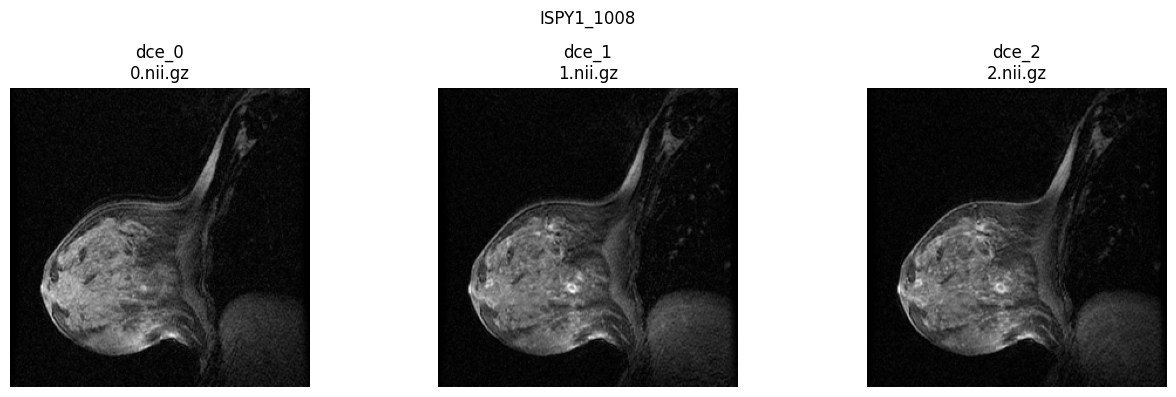


Patient: ISPY1_1037
dce_0: ISPY1_1037_spy1_vis1_dce_aqc_0.nii.gz, shape=(29, 256, 256), range=(0.00, 206.00)
dce_1: ISPY1_1037_spy1_vis1_dce_aqc_2.nii.gz, shape=(29, 256, 256), range=(0.00, 481.00)
dce_2: ISPY1_1037_spy1_vis1_dce_aqc_3.nii.gz, shape=(29, 256, 256), range=(0.00, 421.00)


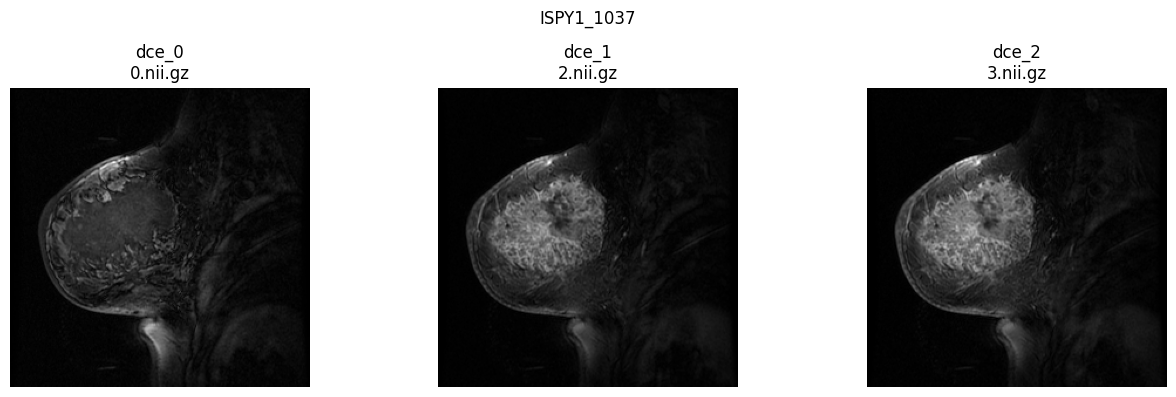


Patient: ISPY1_1029
dce_0: ISPY1_1029_spy1_vis1_dce_aqc_0.nii.gz, shape=(23, 256, 256), range=(0.00, 306.00)
dce_1: ISPY1_1029_spy1_vis1_dce_aqc_1.nii.gz, shape=(23, 256, 256), range=(0.00, 334.00)
dce_2: ISPY1_1029_spy1_vis1_dce_aqc_2.nii.gz, shape=(23, 256, 256), range=(0.00, 317.00)


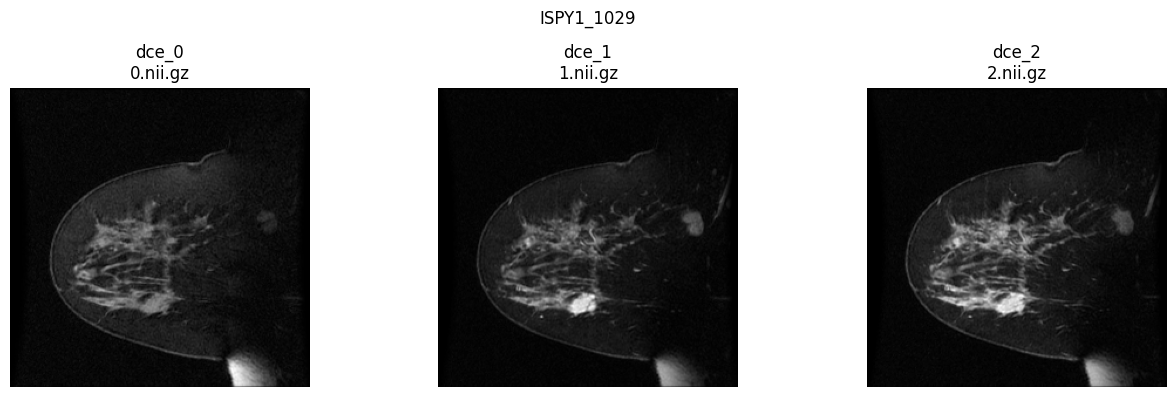

In [35]:
import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np

sample_ids = [
    "ISPY1_1008",
    "ISPY1_1037",
    "ISPY1_1029"
]

for pid in sample_ids:

    row = master_df[master_df["pid"] == pid].iloc[0]

    print(f"\nPatient: {pid}")

    fig, axes = plt.subplots(1, 3, figsize=(13, 4))

    for ch in range(3):

        path = Path(row[f"dce_{ch}"])
        volume = nib.load(str(path)).get_fdata()

        # Use middle volume slice for initial comparison
        z = volume.shape[0] // 2

        axes[ch].imshow(volume[z], cmap="gray")
        axes[ch].set_title(
            f"dce_{ch}\n{path.name.split('_')[-1]}"
        )
        axes[ch].axis("off")

        print(
            f"dce_{ch}: {path.name}, "
            f"shape={volume.shape}, "
            f"range=({volume.min():.2f}, {volume.max():.2f})"
        )

    plt.suptitle(pid)
    plt.tight_layout()
    plt.show()

In [36]:
import nibabel as nib
import numpy as np
from pathlib import Path

train_df = master_df[master_df["split"] == "train"].copy()

channel_mismatches = []
checked = 0

for _, row in train_df.iterrows():

    pid = str(row["pid"])

    for channel in range(3):

        # Original source path from the master CSV
        source_path = Path(row[f"dce_{channel}"])

        # Corresponding nnU-Net training channel
        nnunet_path = (
            DATASET_DIR / "imagesTr" /
            f"{pid}_{channel:04d}.nii.gz"
        )

        source = nib.load(str(source_path)).get_fdata()
        nnunet = nib.load(str(nnunet_path)).get_fdata()

        if source.shape != nnunet.shape:
            channel_mismatches.append(
                (pid, channel, "Shape mismatch")
            )
        elif not np.allclose(source, nnunet, rtol=0, atol=1e-5):
            channel_mismatches.append(
                (pid, channel, "Voxel values differ")
            )

        checked += 1

print("Volumes compared:", checked)
print("Channel mismatches:", len(channel_mismatches))

if channel_mismatches:
    print(channel_mismatches[:20])
else:
    print("All training channels match the CSV mapping.")

Volumes compared: 360
Channel mismatches: 0
All training channels match the CSV mapping.


In [37]:
import cv2
import numpy as np
import nibabel as nib
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

def extract_eval_crops(row, pred_dir):

    pid = str(row["pid"])

    # Always follow CSV channel ordering
    volumes = [
        nib.load(str(row[f"dce_{ch}"])).get_fdata().astype(np.float32)
        for ch in range(3)
    ]

    mask_path = pred_dir / f"{pid}.nii.gz"
    mask = nib.load(str(mask_path)).get_fdata() > 0

    assert all(v.shape == mask.shape for v in volumes), pid

    coords = np.argwhere(mask)

    if len(coords) == 0:
        raise ValueError(f"Empty tumour mask: {pid}")

    _, y_min, x_min = coords.min(axis=0)
    _, y_max, x_max = coords.max(axis=0)

    center_y = (y_min + y_max) // 2
    center_x = (x_min + x_max) // 2

    half = 64

    y1, y2 = center_y - half, center_y + half
    x1, x2 = center_x - half, center_x + half

    normalized_volumes = []

    for volume in volumes:
        low, high = np.percentile(volume, [1, 99])

        normalized_volumes.append(
            np.clip(
                (volume - low) / (high - low + 1e-8),
                0, 1
            )
        )

    tumour_slices = np.where(mask.sum(axis=(1, 2)) > 0)[0]

    crops = []

    for z in tumour_slices:

        channels = []

        for volume in normalized_volumes:

            padded = np.pad(
                volume[z],
                ((half, half), (half, half)),
                mode="constant"
            )

            crop = padded[
                y1 + half:y2 + half,
                x1 + half:x2 + half
            ]

            crop = cv2.resize(
                crop,
                (224, 224),
                interpolation=cv2.INTER_LINEAR
            )

            channels.append(crop)

        crop = np.stack(channels, axis=-1)
        crops.append(np.round(crop * 255).astype(np.uint8))

    return np.stack(crops), tumour_slices


eval_metadata = []
eval_failures = []

for split_name, pred_dir in [
    ("validation", VALIDATION_PRED_DIR),
    ("test", TEST_PRED_DIR)
]:

    subset = master_df[master_df["split"] == split_name]

    for _, row in tqdm(
        subset.iterrows(),
        total=len(subset),
        desc=f"Extracting {split_name}"
    ):

        pid = str(row["pid"])

        try:
            crops, slices = extract_eval_crops(row, pred_dir)

            output_path = CROP_DIR / f"{pid}.npz"

            np.savez_compressed(
                output_path,
                crops=crops,
                slice_indices=slices
            )

            eval_metadata.append({
                "patient_id": pid,
                "split": split_name,
                "num_tumour_slices": len(slices),
                "crop_shape": str(crops.shape),
                "file": str(output_path)
            })

        except Exception as e:
            eval_failures.append({
                "patient_id": pid,
                "split": split_name,
                "error": str(e)
            })

eval_metadata_df = pd.DataFrame(eval_metadata)
eval_metadata_df.to_csv(
    CROP_DIR / "evaluation_crop_metadata.csv",
    index=False
)

print("\nEvaluation crop summary")
print("Successful:", len(eval_metadata_df))
print("Failed:", len(eval_failures))

if eval_failures:
    display(pd.DataFrame(eval_failures))

Extracting validation:   0%|          | 0/26 [00:00<?, ?it/s]

Extracting test:   0%|          | 0/26 [00:00<?, ?it/s]


Evaluation crop summary
Successful: 52
Failed: 0


In [39]:
all_crop_files = list(CROP_DIR.glob("ISPY1_*.npz"))

print("Total patient crop files:", len(all_crop_files))

assert len(all_crop_files) == 172

for pid in ["ISPY1_1008", "ISPY1_1037", "ISPY1_1029"]:

    data = np.load(CROP_DIR / f"{pid}.npz")

    print(
        pid,
        "| shape:", data["crops"].shape,
        "| dtype:", data["crops"].dtype
    )

print("\nAll 172 patient crop files are present.")

Total patient crop files: 172
ISPY1_1008 | shape: (19, 224, 224, 3) | dtype: uint8
ISPY1_1037 | shape: (27, 224, 224, 3) | dtype: uint8
ISPY1_1029 | shape: (15, 224, 224, 3) | dtype: uint8

All 172 patient crop files are present.


In [40]:
!pip install -q transformers accelerate

In [41]:
import torch
import numpy as np
import pandas as pd
import os
import random

from pathlib import Path
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from transformers import ViTMAEForPreTraining

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", DEVICE)

if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Load pretrained ViT-MAE
MODEL_NAME = "facebook/vit-mae-base"

model = ViTMAEForPreTraining.from_pretrained(
    MODEL_NAME
)

model.config.mask_ratio = 0.75

model = model.to(DEVICE)

print("\nModel loaded successfully!")
print("Image size:", model.config.image_size)
print("Patch size:", model.config.patch_size)
print("Hidden size:", model.config.hidden_size)
print("Number of layers:", model.config.num_hidden_layers)
print("Mask ratio:", model.config.mask_ratio)

Device: cuda
GPU: Tesla T4


Loading weights:   0%|          | 0/334 [00:00<?, ?it/s]


Model loaded successfully!
Image size: 224
Patch size: 16
Hidden size: 768
Number of layers: 12
Mask ratio: 0.75


In [42]:
class BreastMRIDataset(Dataset):

    def __init__(self, crop_dir, patient_ids):

        self.samples = []

        for pid in patient_ids:

            path = crop_dir / f"{pid}.npz"

            data = np.load(path)
            crops = data["crops"]

            for i in range(len(crops)):
                self.samples.append((pid, i))

        self.crop_dir = crop_dir

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):

        pid, slice_idx = self.samples[idx]

        data = np.load(self.crop_dir / f"{pid}.npz")
        image = data["crops"][slice_idx]

        # HWC -> CHW
        image = np.transpose(image, (2, 0, 1))

        # uint8 [0,255] -> float32 [0,1]
        image = torch.tensor(
            image.copy(),
            dtype=torch.float32
        ) / 255.0

        return image


# Only training patients
train_patient_ids = (
    master_df.loc[
        master_df["split"] == "train",
        "patient_id"
    ].tolist()
)

train_dataset = BreastMRIDataset(
    CROP_DIR,
    train_patient_ids
)

BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(DEVICE == "cuda")
)

print("Training patients:", len(train_patient_ids))
print("Training MRI slices:", len(train_dataset))
print("Number of batches:", len(train_loader))

Training patients: 120
Training MRI slices: 3214
Number of batches: 402


In [43]:
model.train()

images = next(iter(train_loader)).to(DEVICE)

print("Input shape:", images.shape)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-5,
    weight_decay=0.05
)

optimizer.zero_grad()

outputs = model(pixel_values=images)

loss = outputs.loss

print("Reconstruction loss:", loss.item())

loss.backward()

print("Backward pass successful!")

optimizer.step()

print("One optimization step completed!")

Input shape: torch.Size([8, 3, 224, 224])
Reconstruction loss: 0.009852394461631775
Backward pass successful!
One optimization step completed!


Epoch 1/5:   0%|          | 0/402 [00:00<?, ?it/s]


Epoch 1: Average reconstruction loss = 0.012032


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 2/5:   0%|          | 0/402 [00:00<?, ?it/s]


Epoch 2: Average reconstruction loss = 0.011722


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (8 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fb80097d760>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fb80097d760>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/


Epoch 5: Average reconstruction loss = 0.011427


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


MAE adaptation completed!


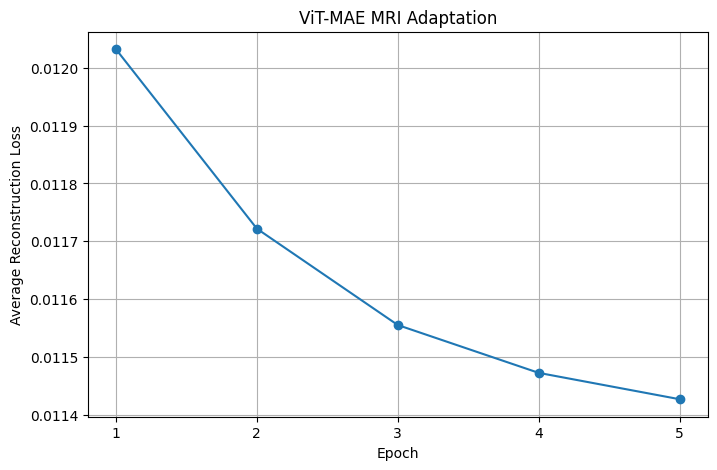

Saved model: /content/drive/MyDrive/Breast_Cancer_AI_Project/models/vit_mae


In [44]:
import torch
import matplotlib.pyplot as plt
import json
from pathlib import Path
from tqdm.auto import tqdm

# Save adapted model in Google Drive
MAE_OUTPUT_DIR = BASE / "models" / "vit_mae"
MAE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 5
LEARNING_RATE = 1e-5

# Keep the MAE masking objective active
model.config.mask_ratio = 0.75

# Optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.05
)

# Mixed precision for Tesla T4
scaler = torch.amp.GradScaler("cuda")

history = []

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0
    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS}"
    )

    for images in progress:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            outputs = model(pixel_values=images)
            loss = outputs.loss

        scaler.scale(loss).backward()

        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()

        progress.set_postfix(
            loss=f"{loss.item():.5f}"
        )

    epoch_loss = running_loss / len(train_loader)

    history.append({
        "epoch": epoch + 1,
        "loss": epoch_loss
    })

    print(
        f"\nEpoch {epoch+1}: "
        f"Average reconstruction loss = {epoch_loss:.6f}"
    )

    # Save checkpoint after every epoch
    checkpoint_dir = MAE_OUTPUT_DIR / f"epoch_{epoch+1}"
    checkpoint_dir.mkdir(exist_ok=True)

    model.save_pretrained(checkpoint_dir)
    optimizer_state = checkpoint_dir / "optimizer.pt"

    torch.save(
        optimizer.state_dict(),
        optimizer_state
    )

    with open(MAE_OUTPUT_DIR / "training_history.json", "w") as f:
        json.dump(history, f, indent=4)

print("\nMAE adaptation completed!")

# Plot reconstruction loss
losses = [item["loss"] for item in history]
epochs = [item["epoch"] for item in history]

plt.figure(figsize=(8, 5))
plt.plot(epochs, losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Average Reconstruction Loss")
plt.title("ViT-MAE MRI Adaptation")
plt.xticks(epochs)
plt.grid(True)
plt.show()

print("Saved model:", MAE_OUTPUT_DIR)

In [47]:
from collections import defaultdict
from tqdm.auto import tqdm

patient_features = defaultdict(list)

with torch.no_grad():

    for images, patient_ids in tqdm(
        feature_loader,
        desc="Extracting ViT-MAE features"
    ):

        images = images.to(DEVICE)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            encoder_output = feature_model.vit(
                pixel_values=images
            )

            # CLS token representation
            features = encoder_output.last_hidden_state[:, 0, :]

        features = features.float().cpu().numpy()

        for pid, feature in zip(patient_ids, features):
            patient_features[pid].append(feature)

# Average slice-level features for each patient
patient_vectors = {}

for pid, vectors in patient_features.items():

    patient_vectors[pid] = np.mean(
        np.stack(vectors),
        axis=0
    )

print("Patients with extracted features:", len(patient_vectors))

# Convert to dataframe
feature_df = pd.DataFrame.from_dict(
    patient_vectors,
    orient="index"
)

feature_df.index.name = "patient_id"
feature_df.columns = [
    f"vitmae_{i}" for i in range(feature_df.shape[1])
]

feature_df = feature_df.reset_index()

print("Feature dataframe shape:", feature_df.shape)
display(feature_df.head())

Extracting ViT-MAE features:   0%|          | 0/281 [00:00<?, ?it/s]

Patients with extracted features: 172
Feature dataframe shape: (172, 769)


,patient_id,vitmae_0,vitmae_1,vitmae_2,vitmae_3,vitmae_4,vitmae_5,vitmae_6,vitmae_7,vitmae_8,...,vitmae_758,vitmae_759,vitmae_760,vitmae_761,vitmae_762,vitmae_763,vitmae_764,vitmae_765,vitmae_766,vitmae_767
0,ISPY1_1001,-0.086857,0.070260,-0.132771,-0.099481,-0.380548,-2.406341,0.007979,0.122718,0.050098,...,-0.100039,0.175530,-0.099827,-0.160829,-0.039261,0.033379,-0.133405,-0.294685,-0.261392,0.081546
1,ISPY1_1002,-0.086232,0.051316,-0.079985,-0.121799,-0.466256,-2.461893,0.010063,0.126202,0.077518,...,-0.060347,0.206217,-0.081309,-0.119800,0.019910,0.037170,-0.113329,-0.305860,-0.261780,0.043345
2,ISPY1_1003,-0.090963,0.059947,-0.132674,-0.123268,-0.381084,-2.434772,-0.056810,0.141279,0.050038,...,-0.062610,0.182212,-0.091414,-0.121930,-0.012091,0.077391,-0.162787,-0.365752,-0.248092,0.026337
3,ISPY1_1004,-0.134079,0.021855,-0.096226,-0.071855,-0.411020,-2.488066,0.007730,0.174335,0.050527,...,-0.036193,0.195144,-0.069090,-0.082124,0.007204,0.027365,-0.116391,-0.272416,-0.221799,0.078645
4,ISPY1_1005,-0.160710,0.018995,-0.151949,-0.088710,-0.421583,-2.420689,0.007132,0.126185,0.053167,...,-0.039489,0.212160,-0.065860,-0.084791,0.006455,0.055735,-0.106188,-0.297787,-0.236221,0.096356


In [48]:
FEATURE_DIR = BASE / "features"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

FEATURE_PATH = FEATURE_DIR / "vit_mae_patient_features.csv"

feature_df.to_csv(FEATURE_PATH, index=False)

print("Saved:", FEATURE_PATH)

Saved: /content/drive/MyDrive/Breast_Cancer_AI_Project/features/vit_mae_patient_features.csv


In [49]:
import pandas as pd
import numpy as np

# Load extracted imaging features
feature_df = pd.read_csv(FEATURE_PATH)

# Merge with master patient information
model_df = master_df.merge(
    feature_df,
    on="patient_id",
    how="inner",
    validate="one_to_one"
)

print("Merged dataset shape:", model_df.shape)
print("\nSplit distribution:")
print(model_df["split"].value_counts())

print("\npCR distribution:")
print(model_df["pCR"].value_counts(dropna=False))

# Verify no patients were lost
assert len(model_df) == 172
assert model_df["patient_id"].nunique() == 172

print("\nPatient merge verified!")

Merged dataset shape: (172, 807)

Split distribution:
split
train         120
validation     26
test           26
Name: count, dtype: int64

pCR distribution:
pCR
0.0    122
1.0     49
NaN      1
Name: count, dtype: int64

Patient merge verified!


In [50]:
clinical_candidates = [
    "age",
    "ER",
    "PR",
    "HR",
    "HER2",
    "HR_HER2_STATUS",
    "bilateral",
    "MRI_LD_Baseline",
    "race_white",
    "race_black",
    "manufacturer",
    "VOI Width",
    "VOI Height",
    "VOI Depth",
    "VOI Volume",
    "HRposHER2neg",
    "TripleNeg",
    "HER2pos"
]

for col in clinical_candidates:

    if col not in model_df.columns:
        continue

    print(f"\n{'='*40}")
    print(col)
    print("Data type:", model_df[col].dtype)
    print("Missing:", model_df[col].isna().sum())
    print("Unique values:", model_df[col].nunique())

    print(model_df[col].value_counts(dropna=False).head(15))


age
Data type: float64
Missing: 0
Unique values: 164
age
50.15    3
40.82    2
60.11    2
53.78    2
44.59    2
49.10    2
53.45    2
45.80    1
48.28    1
49.83    1
41.53    1
49.36    1
42.16    1
35.52    1
68.31    1
Name: count, dtype: int64

ER
Data type: float64
Missing: 2
Unique values: 2
ER
1.0    91
0.0    79
NaN     2
Name: count, dtype: int64

PR
Data type: float64
Missing: 2
Unique values: 2
PR
0.0    95
1.0    75
NaN     2
Name: count, dtype: int64

HR
Data type: float64
Missing: 2
Unique values: 2
HR
1.0    95
0.0    75
NaN     2
Name: count, dtype: int64

HER2
Data type: float64
Missing: 5
Unique values: 2
HER2
0.0    113
1.0     54
NaN      5
Name: count, dtype: int64

HR_HER2_STATUS
Data type: object
Missing: 5
Unique values: 3
HR_HER2_STATUS
HRposHER2neg    69
HER2pos         54
TripleNeg       44
NaN              5
Name: count, dtype: int64

bilateral
Data type: int64
Missing: 0
Unique values: 2
bilateral
0    169
1      3
Name: count, dtype: int64

MRI_LD_Baselin

In [51]:
print(pd.crosstab(
    model_df["split"],
    model_df["pCR"],
    margins=True,
    dropna=False
))

pCR         0.0  1.0  NaN  All
split                         
test         18    8    0   26
train        85   34    1  120
validation   19    7    0   26
All         122   49    0  172


In [52]:

# ==========================================
# STEP 1: DEFINE MODELLING FEATURE GROUPS
# ==========================================

# Clinical and baseline patient/tumour characteristics
clinical_cols = [
    "age",
    "ER",
    "PR",
    "HER2",
    "bilateral",
    "MRI_LD_Baseline"
]

# Segmentation-derived tumour measurements
voi_cols = [
    "VOI Width",
    "VOI Height",
    "VOI Depth",
    "VOI Volume"
]

# Imaging representations extracted from ViT-MAE
image_cols = [
    col for col in feature_df.columns
    if col != "patient_id"
]

# Verify the feature groups
print("Clinical features:", clinical_cols)
print("Number of clinical features:", len(clinical_cols))

print("\nVOI features:", voi_cols)
print("Number of VOI features:", len(voi_cols))

print("\nNumber of imaging features:", len(image_cols))

# Verify that every required column exists
required_cols = clinical_cols + voi_cols + ["pCR", "split", "patient_id"]

missing_cols = [
    col for col in required_cols
    if col not in model_df.columns
]

assert len(missing_cols) == 0, f"Missing columns: {missing_cols}"

# Create split-specific datasets
train_df = model_df[model_df["split"] == "train"].copy()
val_df = model_df[model_df["split"] == "validation"].copy()
test_df = model_df[model_df["split"] == "test"].copy()

# Exclude the one patient with missing pCR from supervised training
train_df = train_df.dropna(subset=["pCR"]).copy()

# Convert target to integer
for df in [train_df, val_df, test_df]:
    df["pCR"] = df["pCR"].astype(int)

# Verify patient counts
print("\nFinal supervised dataset sizes:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nTraining target distribution:")
print(train_df["pCR"].value_counts().sort_index())

print("\nValidation target distribution:")
print(val_df["pCR"].value_counts().sort_index())

print("\nTest target distribution:")
print(test_df["pCR"].value_counts().sort_index())

# Verify that no patient appears in multiple splits
assert set(train_df.patient_id).isdisjoint(set(val_df.patient_id))
assert set(train_df.patient_id).isdisjoint(set(test_df.patient_id))
assert set(val_df.patient_id).isdisjoint(set(test_df.patient_id))

print("\nPatient-level split verification: PASSED")


Clinical features: ['age', 'ER', 'PR', 'HER2', 'bilateral', 'MRI_LD_Baseline']
Number of clinical features: 6

VOI features: ['VOI Width', 'VOI Height', 'VOI Depth', 'VOI Volume']
Number of VOI features: 4

Number of imaging features: 768

Final supervised dataset sizes:
Train: 119
Validation: 26
Test: 26

Training target distribution:
pCR
0    85
1    34
Name: count, dtype: int64

Validation target distribution:
pCR
0    19
1     7
Name: count, dtype: int64

Test target distribution:
pCR
0    18
1     8
Name: count, dtype: int64

Patient-level split verification: PASSED


In [66]:

# ==========================================
# STEP 2: CLINICAL-ONLY LOGISTIC REGRESSION
# ==========================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# 1. Prepare features and target
X_train = train_df[clinical_cols].copy()
y_train = train_df["pCR"].copy()

X_val = val_df[clinical_cols].copy()
y_val = val_df["pCR"].copy()

# 2. Build preprocessing + model pipeline
clinical_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        C=1.0,
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# 3. Train ONLY on training patients
clinical_model.fit(X_train, y_train)

# 4. Predict validation probabilities
val_prob = clinical_model.predict_proba(X_val)[:, 1]

# Initial threshold: 0.7
val_pred = (val_prob >= 0.7).astype(int)

# 5. Evaluate validation performance
print("CLINICAL-ONLY MODEL — VALIDATION RESULTS")
print("=" * 45)

print(f"ROC-AUC:           {roc_auc_score(y_val, val_prob):.4f}")
print(f"PR-AUC:            {average_precision_score(y_val, val_prob):.4f}")
print(f"Accuracy:          {accuracy_score(y_val, val_pred):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_val, val_pred):.4f}")
print(f"Precision:         {precision_score(y_val, val_pred, zero_division=0):.4f}")
print(f"Recall:            {recall_score(y_val, val_pred, zero_division=0):.4f}")
print(f"F1-score:          {f1_score(y_val, val_pred, zero_division=0):.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_val, val_pred))

print("\nClassification report:")
print(classification_report(
    y_val,
    val_pred,
    target_names=["Non-pCR (0)", "pCR (1)"],
    zero_division=0
))

# 6. Inspect learned coefficients
classifier = clinical_model.named_steps["classifier"]

coef_df = pd.DataFrame({
    "Feature": clinical_cols,
    "Coefficient": classifier.coef_[0]
})

coef_df["Absolute_coefficient"] = coef_df["Coefficient"].abs()
coef_df = coef_df.sort_values(
    "Absolute_coefficient",
    ascending=False
)

print("\nStandardised logistic regression coefficients:")
print(coef_df.to_string(index=False))

# 7. Save validation predictions for later comparison
clinical_val_results = pd.DataFrame({
    "patient_id": val_df["patient_id"].values,
    "actual_pCR": y_val.values,
    "predicted_probability": val_prob,
    "predicted_pCR_at_0.5": val_pred
})

print("\nValidation predictions:")
print(clinical_val_results.head(10))


CLINICAL-ONLY MODEL — VALIDATION RESULTS
ROC-AUC:           0.6316
PR-AUC:            0.4121
Accuracy:          0.7308
Balanced accuracy: 0.6353
Precision:         0.5000
Recall:            0.4286
F1-score:          0.4615

Confusion matrix:
[[16  3]
 [ 4  3]]

Classification report:
              precision    recall  f1-score   support

 Non-pCR (0)       0.80      0.84      0.82        19
     pCR (1)       0.50      0.43      0.46         7

    accuracy                           0.73        26
   macro avg       0.65      0.64      0.64        26
weighted avg       0.72      0.73      0.72        26


Standardised logistic regression coefficients:
        Feature  Coefficient  Absolute_coefficient
             ER    -0.809926              0.809926
           HER2     0.690129              0.690129
MRI_LD_Baseline    -0.348871              0.348871
            age    -0.201130              0.201130
      bilateral     0.143942              0.143942
             PR    -0.085975      

In [67]:

# ==========================================
# COMBINED PIPELINE BOTH CLINICAL AND IMAGES
# ==========================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

corrected_preprocessor = ColumnTransformer([
    (
        "clinical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        clinical_cols
    ),
    (
        "imaging",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("pca", PCA(random_state=42)),
            ("pca_scaler", StandardScaler())
        ]),
        image_cols
    )
])

corrected_pipeline = Pipeline([
    ("preprocessor", corrected_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=3000,
        random_state=42
    ))
])

corrected_param_grid = {
    "preprocessor__imaging__pca__n_components": [8, 16, 32, 64],
    "classifier__C": [0.001, 0.01, 0.1, 1, 10],
    "classifier__class_weight": ["balanced", None]
}

corrected_search = GridSearchCV(
    corrected_pipeline,
    corrected_param_grid,
    scoring="roc_auc",
    cv=StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    n_jobs=-1,
    return_train_score=True
)

# Training data only
corrected_search.fit(X_comb_train, y_train)

print("Best parameters:")
print(corrected_search.best_params_)

print("\nBest CV ROC-AUC:")
print(round(corrected_search.best_score_, 4))

# Validation evaluation
corrected_model = corrected_search.best_estimator_

corrected_val_prob = corrected_model.predict_proba(X_comb_val)[:, 1]
corrected_val_pred = (corrected_val_prob >= 0.5).astype(int)

print("\nCORRECTED COMBINED MODEL")
print("ROC-AUC:", round(roc_auc_score(y_val, corrected_val_prob), 4))
print("PR-AUC:", round(average_precision_score(y_val, corrected_val_prob), 4))
print("Accuracy:", round(accuracy_score(y_val, corrected_val_pred), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_val, corrected_val_pred), 4))
print("Precision:", round(precision_score(y_val, corrected_val_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, corrected_val_pred, zero_division=0), 4))
print("F1:", round(f1_score(y_val, corrected_val_pred, zero_division=0), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_val, corrected_val_pred))


Best parameters:
{'classifier__C': 0.01, 'classifier__class_weight': 'balanced', 'preprocessor__imaging__pca__n_components': 16}

Best CV ROC-AUC:
0.7709

CORRECTED COMBINED MODEL
ROC-AUC: 0.7444
PR-AUC: 0.5646
Accuracy: 0.6923
Balanced accuracy: 0.6992
Precision: 0.4545
Recall: 0.7143
F1: 0.5556

Confusion matrix:
[[13  6]
 [ 2  5]]


In [63]:

# ==========================================
# CORRECTED IMAGING-ONLY MODEL WITH PCA
# ==========================================

corrected_imaging_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(random_state=42)),
    ("pca_scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=3000,
        random_state=42
    ))
])

corrected_imaging_grid = {
    "pca__n_components": [8, 16, 32, 64],
    "classifier__C": [0.001, 0.01, 0.1, 1, 10],
    "classifier__class_weight": ["balanced", None]
}

corrected_imaging_search = GridSearchCV(
    corrected_imaging_pipeline,
    corrected_imaging_grid,
    scoring="roc_auc",
    cv=StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    n_jobs=-1,
    return_train_score=True
)

corrected_imaging_search.fit(X_img_train, y_train)

print("Best imaging parameters:")
print(corrected_imaging_search.best_params_)

print("\nBest CV ROC-AUC:")
print(round(corrected_imaging_search.best_score_, 4))

corrected_imaging_model = corrected_imaging_search.best_estimator_

corrected_img_prob = corrected_imaging_model.predict_proba(
    X_img_val
)[:, 1]

corrected_img_pred = (corrected_img_prob >= 0.5).astype(int)

print("\nCORRECTED IMAGING-ONLY VALIDATION")
print("ROC-AUC:",
      round(roc_auc_score(y_val, corrected_img_prob), 4))
print("PR-AUC:",
      round(average_precision_score(y_val, corrected_img_prob), 4))
print("Accuracy:",
      round(accuracy_score(y_val, corrected_img_pred), 4))
print("Balanced accuracy:",
      round(balanced_accuracy_score(y_val, corrected_img_pred), 4))
print("Precision:",
      round(precision_score(y_val, corrected_img_pred, zero_division=0), 4))
print("Recall:",
      round(recall_score(y_val, corrected_img_pred, zero_division=0), 4))
print("F1:",
      round(f1_score(y_val, corrected_img_pred, zero_division=0), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_val, corrected_img_pred))


Best imaging parameters:
{'classifier__C': 10, 'classifier__class_weight': 'balanced', 'pca__n_components': 16}

Best CV ROC-AUC:
0.6664

CORRECTED IMAGING-ONLY VALIDATION
ROC-AUC: 0.5789
PR-AUC: 0.4448
Accuracy: 0.5385
Balanced accuracy: 0.5489
Precision: 0.3077
Recall: 0.5714
F1: 0.4

Confusion matrix:
[[10  9]
 [ 3  4]]


In [64]:

# ==========================================
# IMAGING-ONLY: NO PCA
# ==========================================

no_pca_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=3000,
        random_state=42
    ))
])

no_pca_grid = {
    "classifier__C": [0.0001, 0.001, 0.01, 0.1, 1, 10],
    "classifier__class_weight": ["balanced", None]
}

no_pca_search = GridSearchCV(
    no_pca_pipeline,
    no_pca_grid,
    scoring="roc_auc",
    cv=StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    n_jobs=-1,
    return_train_score=True
)

no_pca_search.fit(X_img_train, y_train)

print("Best parameters:")
print(no_pca_search.best_params_)

print("\nBest CV ROC-AUC:")
print(round(no_pca_search.best_score_, 4))

no_pca_model = no_pca_search.best_estimator_

no_pca_prob = no_pca_model.predict_proba(X_img_val)[:, 1]
no_pca_pred = (no_pca_prob >= 0.5).astype(int)

print("\nIMAGING-ONLY WITHOUT PCA")
print("ROC-AUC:", round(roc_auc_score(y_val, no_pca_prob), 4))
print("PR-AUC:", round(average_precision_score(y_val, no_pca_prob), 4))
print("Accuracy:", round(accuracy_score(y_val, no_pca_pred), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_val, no_pca_pred), 4))
print("F1:", round(f1_score(y_val, no_pca_pred, zero_division=0), 4))

print("\nConfusion matrix:")
print(confusion_matrix(y_val, no_pca_pred))


Best parameters:
{'classifier__C': 0.0001, 'classifier__class_weight': 'balanced'}

Best CV ROC-AUC:
0.6118

IMAGING-ONLY WITHOUT PCA
ROC-AUC: 0.5338
PR-AUC: 0.418
Accuracy: 0.5769
Balanced accuracy: 0.5752
F1: 0.4211

Confusion matrix:
[[11  8]
 [ 3  4]]
